# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 1
# Install Dependencies
# =============================================================================

In [1]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 1
# Install Dependencies
# =============================================================================

!pip install -q segmentation-models-pytorch
!pip install -q albumentations
!pip install -q torchmetrics
!pip install -q medpy
!pip install -q grad-cam

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.0 MB/s eta 0:00:0000:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.3/156.3 kB 3.9 MB/s eta 0:00:0000:01
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 2
# Import Libraries
# =============================================================================

In [2]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 2
# Import Libraries
# =============================================================================

# =============================================================================
# STANDARD LIBRARIES
# =============================================================================
import os
import gc
import cv2
import json
import copy
import random
import warnings
from pathlib import Path

# =============================================================================
# NUMERICAL COMPUTATION
# =============================================================================
import numpy as np
import pandas as pd

# =============================================================================
# VISUALIZATION
# =============================================================================
import matplotlib.pyplot as plt

# =============================================================================
# PYTORCH
# =============================================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import autocast, GradScaler

# =============================================================================
# SEGMENTATION MODELS PYTORCH
# =============================================================================
import segmentation_models_pytorch as smp

# REVISI (Version 13): untuk menutup lubang internal pada mask prediksi
# (lihat postprocess_mask)
from scipy.ndimage import binary_fill_holes

# =============================================================================
# ALBUMENTATIONS
# =============================================================================
import albumentations as A
from albumentations.pytorch import ToTensorV2

# =============================================================================
# TORCHMETRICS
# =============================================================================
from torchmetrics.classification import (
    BinaryAccuracy,
    BinaryPrecision,
    BinaryRecall
)

# =============================================================================
# HD95
# =============================================================================
from medpy.metric.binary import hd95

# =============================================================================
# PROGRESS BAR
# =============================================================================
from tqdm.auto import tqdm

# =============================================================================
# WARNINGS
# =============================================================================
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

# =============================================================================
# REVISI (Version 17): catat waktu mulai notebook sedini mungkin, untuk
# menghitung total durasi keseluruhan proses (bukan cuma training loop)
# di cell Experiment Summary nanti.
# =============================================================================
import time
NOTEBOOK_START_TIME = time.time()


def format_duration(seconds: float) -> str:
    """Ubah durasi dalam detik menjadi string "Xj Ym Zd" yang mudah dibaca."""
    hours, remainder = divmod(int(seconds), 3600)
    minutes, secs = divmod(remainder, 60)
    return f"{hours} jam {minutes} menit {secs} detik"


/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

Libraries imported successfully.


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 3
# Global Configuration
# =============================================================================

In [3]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 3
# Global Configuration
# =============================================================================

# =============================================================================
# RANDOM SEED
# =============================================================================
SEED = 42

# =============================================================================
# DATASET (Version 9)
# =============================================================================
# Dataset gabungan 6 sumber (semua citra berisi polip, tanpa citra normal):
#   BKAI-IGH-NeoPolyp (1.000) + CVC-ClinicDB (612) + CVC-ColonDB (380) +
#   ETIS-LaribPolypDB (196) + Kvasir (1.000) + HyperKvasir Polyp (990)
#   = 4.178 citra total
DATASET_NAME = "Segmentation_Polyp_Colon_PixelT-1"

# =============================================================================
# IMAGE
# =============================================================================
IMG_SIZE = 512

# =============================================================================
# AUGMENTATION PARAMETERS (Version 9)
# =============================================================================
# Single source of truth dipakai BAIK oleh train_transform (Cell 7) MAUPUN
# cell contoh visualisasi augmentasi (Cell 7b), supaya keduanya tidak pernah
# lagi tidak sinkron.
#
# Nilai berikut adalah titik tengah yang disengaja antara permintaan awal
# (rotasi 35 deg, shift 0.3, zoom 40%) dan pipeline konservatif sebelumnya
# (rotasi 15 deg, shift 0.05, zoom 10%):
#   - Dataset sekarang 4.178 citra (2,6x lebih besar dari sebelumnya) ->
#     risiko overfitting lebih rendah -> augmentasi boleh sedikit lebih kuat.
#   - TAPI beberapa sumber dataset (ETIS-LaribPolypDB, CVC-ColonDB) dikenal
#     berisi banyak polip berukuran kecil/samar -> shift dan zoom yang
#     terlalu agresif (0.3 / 40%) berisiko menggeser/mengecilkan polip
#     kecil ini sampai nyaris tak terlihat oleh model.
AUGMENT_ROTATE_LIMIT = 25    # rotasi acak +/- derajat
AUGMENT_SHIFT_LIMIT = 0.15   # width/height shift, fraksi dari sisi citra
AUGMENT_ZOOM_LIMIT = 0.15    # variasi skala (zoom in/out), fraksi

# =============================================================================
# TRAINING
# =============================================================================
BATCH_SIZE = 16

# REVISI (Version 16): ditetapkan 130 (keputusan final untuk konsistensi
# penelitian). Boundary Loss tetap dihapus (lihat USE_BOUNDARY_LOSS di
# bawah) -- manfaat kecepatan/stabilitas dari penghapusannya tetap
# didapat pada budget 130 epoch ini, terlepas dari epoch tidak dinaikkan
# lagi. Catatan: pola 'Best Epoch dekat batas' pada run-run sebelumnya
# sebagian adalah artefak CosineAnnealingLR (LR mencapai titik terendah
# tepat di epoch terakhir) -- bukan bukti kuat butuh epoch lebih banyak.
NUM_EPOCHS = 130

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

NUM_WORKERS = 2
PIN_MEMORY = True

# =============================================================================
# MODEL
# =============================================================================
MODEL_NAME = "UNet"

ENCODER_NAME = "resnet50"
ENCODER_WEIGHTS = "imagenet"

DECODER_ATTENTION = "scse"

IN_CHANNELS = 3
CLASSES = 1

# =============================================================================
# TRAINING STRATEGY
# =============================================================================
FREEZE_ENCODER = True
UNFREEZE_EPOCH = 5

# Differential learning rate applied to the encoder once unfrozen.
# Encoder already carries useful ImageNet features -> fine-tune gently.
# REVISI (Version 18): 0.2 -> 0.25. Konvergensi Version 16/17 terbukti
# bersih (Best Epoch 103/121, early stopping genuine terpicu, bukan
# mepet ke batas epoch) -- ada ruang aman untuk fine-tuning encoder
# sedikit lebih agresif tanpa risiko overfitting berarti, karena
# EARLY_STOPPING_PATIENCE tetap jadi jaring pengaman yang sama.
ENCODER_LR_MULTIPLIER = 0.25

# LR warmup before Cosine Annealing takes over (still same scheduler family
# named in the proposal, only adding a short linear warmup phase).
WARMUP_EPOCHS = 3

USE_AMP = True

# TTA is now genuinely implemented: flip-based (original + horizontal +
# vertical) combined with multi-scale (see MULTISCALE_TTA_SCALES below).
USE_TTA = True

# Multi-scale TTA: run inference at multiple resolutions (relative to
# IMG_SIZE, kept as multiples of 32 for ResNet50 stride-safety) and average
# the probability maps. Applied together with flip-TTA during final
# evaluation, threshold search, prediction visualization, and single-image
# inference (NOT inside the training loop, to keep training speed
# unaffected).
#
# NARROWED from Version 4's [0.75, 1.0, 1.25]: the encoder's BatchNorm
# statistics are calibrated at training resolution (512px, no scale-jitter
# augmentation), so evaluating far from that resolution can push the
# encoder outside its calibrated distribution and hurt rather than help.
# Version 4 also widened this range AND changed the loss weights AND
# extended epochs simultaneously, without an ablation to isolate causes.
# Version 5 makes ONE evidence-motivated change here (narrower range) while
# reverting loss weights to Version 3's better-performing setting (see
# below), so future changes can be attributed more confidently. Set
# USE_MULTISCALE_TTA = False to compare against flip-only TTA if you want a
# clean ablation before finalizing for deployment.
USE_MULTISCALE_TTA = True
# REVISI (Version 13): [0.85,1.0,1.15] -> 5-way [0.85,0.95,1.0,1.05,1.15].
# Memperapat grid skala (bukan memperlebar rentang) untuk cakupan lebih
# halus saat inferensi -- murni menambah biaya komputasi inferensi, TIDAK
# menyentuh training sama sekali, jadi tidak ada risiko baru.
MULTISCALE_TTA_SCALES = [0.85, 0.95, 1.0, 1.05, 1.15]

USE_GRADIENT_CLIPPING = True
GRADIENT_CLIP_VALUE = 1.0

# =============================================================================
# EXPONENTIAL MOVING AVERAGE (EMA)
# =============================================================================
USE_EMA = True
EMA_DECAY = 0.999

# =============================================================================
# LOSS FUNCTION
# =============================================================================
# REVERTED to Version 3's weights. Version 4 shifted weight toward Focal
# Tversky (BCE 0.20->0.15, Tversky 0.40->0.45) hypothesizing it would help
# since pos_weight already handles imbalance -- but Version 4's actual
# result (Dice 0.9324, IoU 0.9083) was WORSE than Version 3's (Dice 0.9383,
# IoU 0.9133). Since Version 4 changed epochs/scales/weights all at once,
# we can't be certain this specific change caused the regression, but given
# a choice between an empirically-worse and empirically-better setting with
# no ablation to distinguish confounds, reverting to the proven one is the
# more defensible default for a model going into production.
# REVISI (Version 18): tambah Lovasz-Hinge Loss -- surrogate diferensiabel
# LANGSUNG untuk IoU/Jaccard (bukan proxy seperti Dice/BCE), menyasar
# target IoU>95 secara eksplisit. Bobot direalokasi: BCE dikurangi lagi
# (komponen paling generik), Dice & Tversky sedikit dikurangi untuk
# memberi ruang Lovasz TANPA membuat total bobot melonjak jauh dari 1.0
# (menjaga skala gradien tetap familiar/stabil terhadap run-run
# sebelumnya). Tversky alpha/beta (klinis, prioritas Recall) TETAP tidak
# disentuh.
BCE_WEIGHT = 0.10
DICE_WEIGHT = 0.40
TVERSKY_WEIGHT = 0.35
LOVASZ_WEIGHT = 0.15

# Tversky: alpha penalizes False Positives, beta penalizes False Negatives.
# Set beta > alpha to prioritize RECALL (missing a polyp is clinically worse
# than a false alarm) -- consistent with the medical justification already
# stated in the proposal (Bab 2.19).
TVERSKY_ALPHA = 0.30
TVERSKY_BETA = 0.70

# Focal Tversky gamma: focuses training on hard / small lesions.
FOCAL_TVERSKY_GAMMA = 0.75

# pos_weight for BCE is computed empirically from the training set
# (see Class Imbalance Analysis cell) and capped to this range for stability.
POS_WEIGHT_MIN = 1.0
POS_WEIGHT_MAX = 20.0
POS_WEIGHT_SAMPLE_SIZE = 300

# =============================================================================
# BOUNDARY LOSS (Version 7, OPTIONAL -- OFF by default)
# =============================================================================
# Adds an explicit boundary-precision term to the loss, based on a signed
# distance transform of the ground truth (Kervadec et al., 2019). Targets
# HD95 specifically. Requires a full retraining run to take effect --
# toggling this alone does nothing to an already-trained model. Previously
# left OFF by default because it was unvalidated against Version 5/6's
# proven setting.
# REVISI (Version 15): DIMATIKAN PERMANEN setelah audit menyeluruh:
# (1) Terbukti jadi bottleneck CPU parah -- distance transform per-sampel
#     per-batch di CPU (cv2.distanceTransform), memaksa GPU menunggu.
#     Penyebab utama training Scenario 2 memakan >13 jam & sesi Kaggle
#     mati mendadak (kemungkinan kehabisan kuota storage/waktu sesi).
# (2) TIDAK terbukti membantu -- HD95 justru memburuk (14.75->15.23px)
#     saat diaktifkan di Version 10-14, dan Dice terbaik sepanjang
#     seluruh eksperimen (0.9571) justru dicapai TANPA Boundary Loss.
# (3) Dibandingkan dengan notebook segmentasi U-Net lain (kanker
#     paru-paru, LC25000 dataset) yang mencapai hasil baik hanya dengan
#     BCE+Dice+Focal Loss -- tanpa Boundary Loss sama sekali, dan tanpa
#     mengukur HD95 secara eksplisit.
# Boundary Loss adalah teknik dari Kervadec et al. (2019) untuk kasus
# ekstrem (objek sangat tipis + class imbalance parah, mis. pembuluh
# darah) -- bukan kebutuhan dasar untuk segmentasi polip.
USE_BOUNDARY_LOSS = False
BOUNDARY_LOSS_WEIGHT = 0.15   # tidak berpengaruh selama flag di atas False

# =============================================================================
# POST-PROCESSING (applied to predicted masks before final metric computation)
# =============================================================================
# REVISI (Version 12): 40 -> 25px. ETIS-LaribPolypDB dan CVC-ColonDB
# dikenal memuat banyak polip berukuran kecil -- ambang 40px berisiko
# membuang prediksi polip kecil yang genuinely benar sebagai 'blob noise'.
POST_PROCESS_MIN_AREA = 25   # pixels, at 512x512 resolution
POST_PROCESS_KERNEL_SIZE = 3

# Contour smoothing (Version 7): light regularization of jagged pixel-level
# boundaries left over from morphological open/close. Does NOT require
# retraining -- can be tested directly against an already-trained model by
# re-running evaluation cells. Safe to leave ON; epsilon is small enough
# that it only removes small "staircase" noise, not genuine shape detail.
USE_CONTOUR_SMOOTHING = True
CONTOUR_SMOOTHING_EPSILON_RATIO = 0.005  # fraction of contour perimeter

# =============================================================================
# GRAD-CAM VISUAL SCHEME (Version 8)
# =============================================================================
# REVISI: kembali memakai visualisasi BAWAAN library pytorch-grad-cam
# (show_cam_on_image, colormap jet standar) alih-alih skema warna kustom
# merah/biru berbasis threshold -- lihat Cell "Grad-CAM Visualization".

# =============================================================================
# DEPLOYMENT / INFERENCE
# =============================================================================
# Minimum predicted polyp area (as % of total image pixels) required before
# reporting "Polyp Detected", to avoid single-pixel false positives from
# triggering a positive result. Shared by Single Image Inference and the
# deployment-ready inference function (Cell 34).
MIN_POLYP_AREA_PERCENT = 0.1

# =============================================================================
# THRESHOLD SEARCH
# =============================================================================
THRESHOLD_START = 0.10
THRESHOLD_END = 0.90
THRESHOLD_STEP = 0.05

BEST_THRESHOLD = 0.50

# =============================================================================
# EARLY STOPPING
# =============================================================================
# REVISI (Version 16): ditetapkan 18 (keputusan final, dikalibrasi untuk
# NUM_EPOCHS=130 -- proporsi ~14%, konsisten dengan nilai yang sudah
# terbukti bekerja baik di run-run sebelumnya). Overfitting dijaga oleh
# mekanisme patience ini, bukan oleh NUM_EPOCHS.
EARLY_STOPPING_PATIENCE = 18

# =============================================================================
# CHECKPOINT MANAGEMENT (Version 15)
# =============================================================================
# REVISI: sebelumnya backup checkpoint dibuat SETIAP 5 epoch tanpa dihapus
# -- 130 epoch bisa menghasilkan ~26 file backup penuh (model+EMA+
# optimizer+scheduler state, masing-masing ratusan MB), berisiko memenuhi
# kuota storage /kaggle/working dan (diduga) berkontribusi pada sesi
# Kaggle yang tiba-tiba mati. Sekarang: interval diperlebar DAN backup
# lama otomatis dihapus, menyisakan jumlah terbatas + checkpoint
# terbaru + best model saja.
BACKUP_INTERVAL = 20        # backup checkpoint tiap N epoch (dulu: 5)
MAX_BACKUPS_TO_KEEP = 2     # backup lama otomatis dihapus, sisakan N terbaru

# =============================================================================
# OUTPUT
# =============================================================================
OUTPUT_DIR = Path("/kaggle/working")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_SAVE_NAME = "best_model.pth"
CHECKPOINT_NAME = "pixelt_checkpoint.pth"
CHECKPOINT_PATH = OUTPUT_DIR / CHECKPOINT_NAME

print("Global configuration loaded.")

Global configuration loaded.


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 4
# Environment Setup
# =============================================================================

In [4]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 4
# Environment Setup
# =============================================================================

def set_seed(seed: int = SEED):
    """
    Set random seed for reproducibility.
    """

    random.seed(seed)
    np.random.seed(seed)

    os.environ["PYTHONHASHSEED"] = str(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed()

# =============================================================================
# DEVICE
# =============================================================================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =============================================================================
# CLEAN MEMORY
# =============================================================================
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# =============================================================================
# SHOW ENVIRONMENT
# =============================================================================
print("=" * 70)
print("PIXEL-T ENVIRONMENT")
print("=" * 70)

print(f"Device              : {DEVICE}")

if DEVICE.type == "cuda":
    print(f"GPU                 : {torch.cuda.get_device_name(0)}")
    print(f"CUDA Version        : {torch.version.cuda}")

print("-" * 70)

print(f"Image Size          : {IMG_SIZE}")
print(f"Batch Size          : {BATCH_SIZE}")
print(f"Epochs              : {NUM_EPOCHS}")

print("-" * 70)

print(f"Model               : {MODEL_NAME}")
print(f"Encoder             : {ENCODER_NAME}")
print(f"Encoder Weights     : {ENCODER_WEIGHTS}")
print(f"Decoder Attention   : {DECODER_ATTENTION}")

print("-" * 70)

print(f"Base Learning Rate  : {LEARNING_RATE}")
print(f"Encoder LR Mult.    : {ENCODER_LR_MULTIPLIER}")
print(f"Warmup Epochs       : {WARMUP_EPOCHS}")
print(f"Weight Decay        : {WEIGHT_DECAY}")

print("-" * 70)

print(f"AMP                 : {USE_AMP}")
print(f"TTA                 : {USE_TTA}")
print(f"EMA                 : {USE_EMA} (decay={EMA_DECAY})")
print(f"Freeze Encoder      : {FREEZE_ENCODER}")

print("=" * 70)

PIXEL-T ENVIRONMENT
Device              : cuda
GPU                 : Tesla T4
CUDA Version        : 12.6
----------------------------------------------------------------------
Image Size          : 512
Batch Size          : 16
Epochs              : 130
----------------------------------------------------------------------
Model               : UNet
Encoder             : resnet50
Encoder Weights     : imagenet
Decoder Attention   : scse
----------------------------------------------------------------------
Base Learning Rate  : 0.0001
Encoder LR Mult.    : 0.25
Warmup Epochs       : 3
Weight Decay        : 0.0001
----------------------------------------------------------------------
AMP                 : True
TTA                 : True
EMA                 : True (decay=0.999)
Freeze Encoder      : True


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 5
# Dataset Configuration
# =============================================================================

In [5]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 5
# Dataset Configuration
# =============================================================================
# CATATAN (Version 9): dataset sudah diganti total menjadi gabungan 6 sumber
# (semua citra polip-positif, TIDAK ADA lagi citra "normal"):
#   BKAI-IGH-NeoPolyp (1.000) + CVC-ClinicDB (612) + CVC-ColonDB (380) +
#   ETIS-LaribPolypDB (196) + Kvasir (1.000) + HyperKvasir Polyp (990)
#   = 4.178 citra total
# KAGGLE_INPUT di bawah sudah diarahkan ke dataset baru ini (folder Kaggle
# "segmentation-polyp-colon-pixelt-3"). Sel-sel evaluasi (Hallucination Rate,
# Polyp-Only vs Full Test Set) sudah menangani kasus 0 citra normal secara
# otomatis (guard division-by-zero), jadi tidak perlu diubah manual.
# =============================================================================

KAGGLE_INPUT = Path(
    "/kaggle/input/datasets/kharisnevilleawuy/"
    "segmentation-polyp-colon-pixelt-3/Segmentation_Polyp_Colon_PixelT-1"
)

TRAIN_IMAGE_DIR = KAGGLE_INPUT / "train" / "images"
TRAIN_MASK_DIR  = KAGGLE_INPUT / "train" / "masks"

VAL_IMAGE_DIR = KAGGLE_INPUT / "val" / "images"
VAL_MASK_DIR  = KAGGLE_INPUT / "val" / "masks"

TEST_IMAGE_DIR = KAGGLE_INPUT / "test" / "images"
TEST_MASK_DIR  = KAGGLE_INPUT / "test" / "masks"

VALID_EXTENSIONS = (".jpg", ".jpeg", ".png")

print("=" * 70)
print("DATASET CONFIGURATION")
print("=" * 70)

print(f"Dataset Root : {KAGGLE_INPUT}")

print("-" * 70)

print(f"Train Images : {TRAIN_IMAGE_DIR}")
print(f"Train Masks  : {TRAIN_MASK_DIR}")

print("-" * 70)

print(f"Val Images   : {VAL_IMAGE_DIR}")
print(f"Val Masks    : {VAL_MASK_DIR}")

print("-" * 70)

print(f"Test Images  : {TEST_IMAGE_DIR}")
print(f"Test Masks   : {TEST_MASK_DIR}")

print("=" * 70)

DATASET CONFIGURATION
Dataset Root : /kaggle/input/datasets/kharisnevilleawuy/segmentation-polyp-colon-pixelt-3/Segmentation_Polyp_Colon_PixelT-1
----------------------------------------------------------------------
Train Images : /kaggle/input/datasets/kharisnevilleawuy/segmentation-polyp-colon-pixelt-3/Segmentation_Polyp_Colon_PixelT-1/train/images
Train Masks  : /kaggle/input/datasets/kharisnevilleawuy/segmentation-polyp-colon-pixelt-3/Segmentation_Polyp_Colon_PixelT-1/train/masks
----------------------------------------------------------------------
Val Images   : /kaggle/input/datasets/kharisnevilleawuy/segmentation-polyp-colon-pixelt-3/Segmentation_Polyp_Colon_PixelT-1/val/images
Val Masks    : /kaggle/input/datasets/kharisnevilleawuy/segmentation-polyp-colon-pixelt-3/Segmentation_Polyp_Colon_PixelT-1/val/masks
----------------------------------------------------------------------
Test Images  : /kaggle/input/datasets/kharisnevilleawuy/segmentation-polyp-colon-pixelt-3/Segmentat

# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 6
# Dataset Verification
# =============================================================================

In [6]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 6
# Dataset Verification
# =============================================================================

def get_image_files(folder: Path):
    files = []
    for ext in VALID_EXTENSIONS:
        files.extend(folder.glob(f"*{ext}"))
        files.extend(folder.glob(f"*{ext.upper()}"))
    return sorted(files)


def verify_dataset(image_dir: Path, mask_dir: Path, split_name: str):

    if not image_dir.exists():
        raise FileNotFoundError(f"{split_name} image directory not found:\n{image_dir}")

    if not mask_dir.exists():
        raise FileNotFoundError(f"{split_name} mask directory not found:\n{mask_dir}")

    image_files = get_image_files(image_dir)
    mask_files = get_image_files(mask_dir)

    image_names = {f.stem for f in image_files}
    mask_names = {f.stem for f in mask_files}

    missing_masks = sorted(image_names - mask_names)
    missing_images = sorted(mask_names - image_names)

    print("=" * 70)
    print(f"{split_name.upper()} DATASET")
    print("=" * 70)

    print(f"Images : {len(image_files)}")
    print(f"Masks  : {len(mask_files)}")

    if len(image_files) == 0:
        raise RuntimeError(f"{split_name} dataset contains no images.")

    if len(mask_files) == 0:
        raise RuntimeError(f"{split_name} dataset contains no masks.")

    if missing_masks or missing_images:

        print("\nDataset Verification : FAILED")

        if missing_masks:
            print(f"\nMissing Masks ({len(missing_masks)}):")
            print(missing_masks[:10])

        if missing_images:
            print(f"\nMissing Images ({len(missing_images)}):")
            print(missing_images[:10])

        raise RuntimeError(f"{split_name} dataset has unmatched image-mask pairs.")

    print("Dataset Verification : PASSED\n")

    return image_files


train_images = verify_dataset(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, "Train")
val_images   = verify_dataset(VAL_IMAGE_DIR, VAL_MASK_DIR, "Validation")
test_images  = verify_dataset(TEST_IMAGE_DIR, TEST_MASK_DIR, "Test")

print("=" * 70)
print("ALL DATASETS VERIFIED SUCCESSFULLY")
print("=" * 70)

print(f"Train Images      : {len(train_images)}")
print(f"Validation Images : {len(val_images)}")
print(f"Test Images       : {len(test_images)}")

print("=" * 70)

TRAIN DATASET
Images : 3342
Masks  : 3342
Dataset Verification : PASSED

VALIDATION DATASET
Images : 418
Masks  : 418
Dataset Verification : PASSED

TEST DATASET
Images : 418
Masks  : 418
Dataset Verification : PASSED

ALL DATASETS VERIFIED SUCCESSFULLY
Train Images      : 3342
Validation Images : 418
Test Images       : 418


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 7
# Audit Kebocoran Data Lintas-Split (Data Leakage Audit)
# =============================================================================

In [7]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 7
# Audit Kebocoran Data Lintas-Split (Data Leakage Audit)
# =============================================================================

def _compute_ahash(image_path, hash_size=8):
    """64-bit average-hash: robust terhadap resize/recompression ringan."""
    img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (hash_size, hash_size), interpolation=cv2.INTER_AREA)
    avg = img.mean()
    return (img > avg).flatten().astype(np.uint8)


def _hamming_distance_matrix(hashes_a, hashes_b):
    """(Na, 64) vs (Nb, 64) uint8 {0,1} arrays -> (Na, Nb) Hamming distances."""
    return (hashes_a[:, None, :] != hashes_b[None, :, :]).sum(axis=2)


print("=" * 70)
print("AUDIT KEBOCORAN DATA LINTAS-SPLIT (DATA LEAKAGE AUDIT)")
print("=" * 70)

HAMMING_DUPLICATE_THRESHOLD = 5  # dari 64 bit; <=5 bit beda = nyaris-duplikat

_leak_splits = {
    "train": train_images,
    "val": val_images,
    "test": test_images,
}

_leak_hashes = {}
for split_name, files in _leak_splits.items():
    print(f"Menghitung hash untuk {split_name} ({len(files)} citra)...")
    _leak_hashes[split_name] = np.stack(
        [_compute_ahash(p) for p in tqdm(files, leave=False)]
    )

_leak_pairs_to_check = [("train", "val"), ("train", "test"), ("val", "test")]
_total_leaks = 0

for split_a, split_b in _leak_pairs_to_check:

    dist_matrix = _hamming_distance_matrix(_leak_hashes[split_a], _leak_hashes[split_b])
    leak_indices = np.argwhere(dist_matrix <= HAMMING_DUPLICATE_THRESHOLD)

    print("-" * 70)
    print(f"{split_a.upper()} vs {split_b.upper()}: {len(leak_indices)} pasangan nyaris-duplikat")

    if len(leak_indices) > 0:
        _total_leaks += len(leak_indices)
        for idx_a, idx_b in leak_indices[:5]:
            name_a = _leak_splits[split_a][idx_a].name
            name_b = _leak_splits[split_b][idx_b].name
            dist = dist_matrix[idx_a, idx_b]
            print(f"    {name_a}  <->  {name_b}   (Hamming dist={dist})")
        if len(leak_indices) > 5:
            print(f"    ... dan {len(leak_indices) - 5} pasangan lainnya")

print("=" * 70)
if _total_leaks == 0:
    print("HASIL: TIDAK ADA indikasi kebocoran data lintas-split terdeteksi.")
    print("Evaluasi test set dapat dianggap murni mengukur generalisasi model.")
else:
    print(f"PERINGATAN: {_total_leaks} indikasi potensi kebocoran data ditemukan.")
    print("Metrik test BERISIKO terinflasi secara artifisial. Pertimbangkan")
    print("menghapus citra yang tumpang tindih ini dari train/val (PERTAHANKAN")
    print("keutuhan test set), lalu upload ulang dataset yang sudah bersih.")
print("=" * 70)

AUDIT KEBOCORAN DATA LINTAS-SPLIT (DATA LEAKAGE AUDIT)
Menghitung hash untuk train (3342 citra)...


  0%|          | 0/3342 [00:00<?, ?it/s]

Menghitung hash untuk val (418 citra)...


  0%|          | 0/418 [00:00<?, ?it/s]

Menghitung hash untuk test (418 citra)...


  0%|          | 0/418 [00:00<?, ?it/s]

----------------------------------------------------------------------
TRAIN vs VAL: 4884 pasangan nyaris-duplikat
    bkai_000001.jpeg  <->  bkai_000693.jpeg   (Hamming dist=5)
    bkai_000004.jpeg  <->  bkai_000198.jpeg   (Hamming dist=2)
    bkai_000004.jpeg  <->  hyperpolyp_000923.jpg   (Hamming dist=5)
    bkai_000005.jpeg  <->  bkai_000301.jpeg   (Hamming dist=5)
    bkai_000008.jpeg  <->  bkai_000028.jpeg   (Hamming dist=5)
    ... dan 4879 pasangan lainnya
----------------------------------------------------------------------
TRAIN vs TEST: 4831 pasangan nyaris-duplikat
    bkai_000004.jpeg  <->  bkai_000974.jpeg   (Hamming dist=5)
    bkai_000005.jpeg  <->  bkai_000952.jpeg   (Hamming dist=4)
    bkai_000008.jpeg  <->  bkai_000914.jpeg   (Hamming dist=4)
    bkai_000009.jpeg  <->  bkai_000407.jpeg   (Hamming dist=5)
    bkai_000010.jpeg  <->  bkai_000141.jpeg   (Hamming dist=5)
    ... dan 4826 pasangan lainnya
------------------------------------------------------------------

# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 8
# Albumentations Transform
# =============================================================================

In [8]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 8
# Albumentations Transform
# =============================================================================
# Added ElasticTransform, GridDistortion (simulate soft-tissue deformation)
# and CoarseDropout (simulate specular reflection / debris occlusion) on top
# of the Version 2 augmentation pipeline -- directly addressing the visual
# challenges you describe in Bab 2.2.2 of the proposal.
#
# REVISI (Version 9): rotation/width-height-shift/zoom sekarang memakai
# AUGMENT_ROTATE_LIMIT / AUGMENT_SHIFT_LIMIT / AUGMENT_ZOOM_LIMIT dari Global
# Configuration -- nilai ini dikalibrasi ulang untuk dataset gabungan 6
# sumber (4.178 citra), lebih kuat dari pipeline sebelumnya tapi tetap jauh
# di bawah permintaan awal (rotasi 35/shift 0.3/zoom 40%) untuk melindungi
# polip kecil dari ETIS-LaribPolypDB & CVC-ColonDB agar tidak tergeser/
# mengecil keluar batas deteksi saat augmentasi.
# =============================================================================

train_transform = A.Compose([
    A.Resize(height=IMG_SIZE, width=IMG_SIZE),

    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),

    # REVISI (Version 9): rotasi/shift/zoom kini memakai AUGMENT_* dari Global
    # Configuration (single source of truth, sinkron dengan cell demo).
    A.Affine(
        scale=(1 - AUGMENT_ZOOM_LIMIT, 1 + AUGMENT_ZOOM_LIMIT),
        translate_percent=(-AUGMENT_SHIFT_LIMIT, AUGMENT_SHIFT_LIMIT),
        rotate=(-AUGMENT_ROTATE_LIMIT, AUGMENT_ROTATE_LIMIT),
        shear=(-10, 10),
        p=0.5
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.2,
        contrast_limit=0.2,
        p=0.5
    ),

    A.CLAHE(
        clip_limit=4.0,
        tile_grid_size=(8, 8),
        p=0.3
    ),

    A.GaussNoise(p=0.2),

    # NEW: simulate soft-tissue deformation
    A.ElasticTransform(
        alpha=40,
        sigma=6,
        p=0.2
    ),

    A.GridDistortion(
        num_steps=5,
        distort_limit=0.2,
        p=0.2
    ),

    # NEW: simulate occlusion by specular reflection / fluid / debris
    A.CoarseDropout(
        num_holes_range=(1, 4),
        hole_height_range=(0.03, 0.08),
        hole_width_range=(0.03, 0.08),
        fill=0,
        p=0.2
    ),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()
])

valid_transform = A.Compose([
    A.Resize(height=IMG_SIZE, width=IMG_SIZE),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()
])

print("=" * 70)
print("ALBUMENTATIONS TRANSFORM CREATED (with clinically-motivated additions)")
print("=" * 70)

ALBUMENTATIONS TRANSFORM CREATED (with clinically-motivated additions)


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 9
# Contoh Visualisasi Augmentasi Data
# =============================================================================

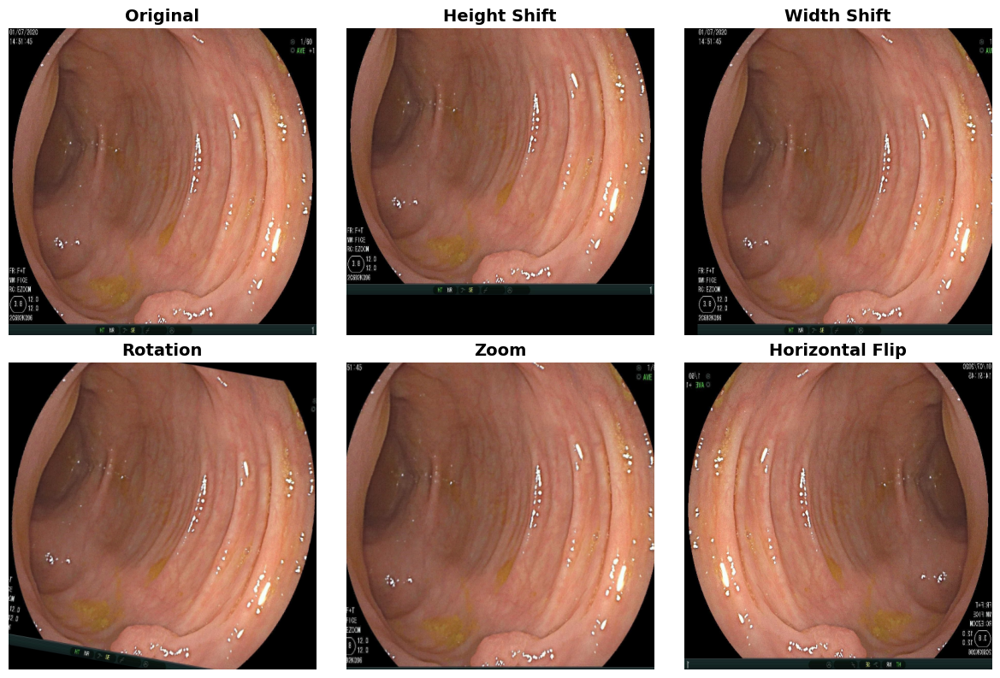

CONTOH AUGMENTASI DATA (nilai sama persis dengan train_transform)
Rotation        : rotasi acak hingga +/-25 derajat
Width Shift     : pergeseran horizontal hingga +/-15% lebar citra
Height Shift    : pergeseran vertikal hingga +/-15% tinggi citra
Zoom            : variasi skala hingga +/-15%
Horizontal Flip : pencerminan horizontal

Disimpan ke: /kaggle/working/augmentation_examples.png


In [9]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 9
# Contoh Visualisasi Augmentasi Data (untuk Bab 3 Metodologi)
# =============================================================================
# REVISI (Version 9): parameter di bawah TIDAK lagi hardcode -- diambil dari
# AUGMENT_ROTATE_LIMIT / AUGMENT_SHIFT_LIMIT / AUGMENT_ZOOM_LIMIT di Global
# Configuration, PERSIS nilai yang sama dipakai oleh train_transform untuk
# training sesungguhnya. Cell ini sekarang benar-benar merepresentasikan
# augmentasi model, bukan sekadar ilustrasi konsep.
# =============================================================================

_demo_image_path = train_images[0]
_demo_image_bgr = cv2.imread(str(_demo_image_path))
_demo_image_rgb = cv2.cvtColor(_demo_image_bgr, cv2.COLOR_BGR2RGB)
_demo_image_rgb = cv2.resize(_demo_image_rgb, (IMG_SIZE, IMG_SIZE))


def _apply_single_augmentation(image, transform, seed):
    random.seed(seed)
    np.random.seed(seed)
    return transform(image=image)["image"]


_height_shift_transform = A.Affine(
    translate_percent={"x": (0, 0), "y": (-AUGMENT_SHIFT_LIMIT, AUGMENT_SHIFT_LIMIT)}, p=1.0
)
_width_shift_transform = A.Affine(
    translate_percent={"x": (-AUGMENT_SHIFT_LIMIT, AUGMENT_SHIFT_LIMIT), "y": (0, 0)}, p=1.0
)
_rotation_transform = A.Rotate(
    limit=AUGMENT_ROTATE_LIMIT, p=1.0, border_mode=cv2.BORDER_CONSTANT, fill=0
)
_zoom_transform = A.Affine(scale=(1 - AUGMENT_ZOOM_LIMIT, 1 + AUGMENT_ZOOM_LIMIT), p=1.0)
_hflip_transform = A.HorizontalFlip(p=1.0)

_augmented_examples = {
    "Original": _demo_image_rgb,
    "Height Shift": _apply_single_augmentation(_demo_image_rgb, _height_shift_transform, seed=1),
    "Width Shift": _apply_single_augmentation(_demo_image_rgb, _width_shift_transform, seed=2),
    "Rotation": _apply_single_augmentation(_demo_image_rgb, _rotation_transform, seed=3),
    "Zoom": _apply_single_augmentation(_demo_image_rgb, _zoom_transform, seed=4),
    "Horizontal Flip": _apply_single_augmentation(_demo_image_rgb, _hflip_transform, seed=5),
}

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for ax, (title, img) in zip(axes, _augmented_examples.items()):
    ax.imshow(img)
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.axis("off")

plt.tight_layout()

augmentation_demo_path = OUTPUT_DIR / "augmentation_examples.png"
plt.savefig(augmentation_demo_path, dpi=150, bbox_inches="tight")
plt.show()

print("=" * 70)
print("CONTOH AUGMENTASI DATA (nilai sama persis dengan train_transform)")
print("=" * 70)
print(f"Rotation        : rotasi acak hingga +/-{AUGMENT_ROTATE_LIMIT} derajat")
print(f"Width Shift     : pergeseran horizontal hingga +/-{AUGMENT_SHIFT_LIMIT*100:.0f}% lebar citra")
print(f"Height Shift    : pergeseran vertikal hingga +/-{AUGMENT_SHIFT_LIMIT*100:.0f}% tinggi citra")
print(f"Zoom            : variasi skala hingga +/-{AUGMENT_ZOOM_LIMIT*100:.0f}%")
print("Horizontal Flip : pencerminan horizontal")
print(f"\nDisimpan ke: {augmentation_demo_path}")
print("=" * 70)

# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 10
# Custom Dataset
# =============================================================================

In [10]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 10
# Custom Dataset
# =============================================================================

class PolypDataset(Dataset):
    """
    Dataset for colorectal polyp segmentation.
    Supports mixed image/mask extensions (.jpg, .jpeg, .png).
    """

    VALID_EXTENSIONS = {
        ".jpg", ".jpeg", ".png",
        ".JPG", ".JPEG", ".PNG"
    }

    def __init__(self, image_files, mask_dir, transform=None):

        self.image_files = sorted(image_files)
        self.mask_dir = Path(mask_dir)
        self.transform = transform

        self.mask_map = {}
        for mask_path in self.mask_dir.iterdir():
            if mask_path.is_file() and mask_path.suffix in self.VALID_EXTENSIONS:
                self.mask_map[mask_path.stem] = mask_path

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, index):

        image_path = self.image_files[index]

        mask_path = self.mask_map.get(image_path.stem)
        if mask_path is None:
            raise FileNotFoundError(f"Mask not found for image: {image_path.name}")

        image = cv2.imread(str(image_path))
        if image is None:
            raise FileNotFoundError(f"Cannot read image: {image_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # ==========================================================
        # ROBUST MASK READING (Version 5 fix)
        # ==========================================================
        # Read with IMREAD_UNCHANGED instead of IMREAD_GRAYSCALE. If the
        # mask happens to be stored with color channels (not pure
        # black/white), a naive grayscale (luminance) conversion can push
        # a strongly-colored annotation (e.g. pure red) below the 127
        # threshold and silently erase it. Taking the max across channels
        # guarantees any colored annotation is preserved as foreground.
        # This is a no-op if masks are already clean single-channel
        # black/white images.
        mask_raw = cv2.imread(str(mask_path), cv2.IMREAD_UNCHANGED)
        if mask_raw is None:
            raise FileNotFoundError(f"Cannot read mask: {mask_path}")

        if mask_raw.ndim == 3:
            mask_gray = mask_raw.max(axis=2)
        else:
            mask_gray = mask_raw

        mask = (mask_gray > 127).astype(np.float32)

        if self.transform is not None:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"]

        if not isinstance(mask, torch.Tensor):
            mask = torch.from_numpy(mask)

        # ==========================================================
        # RE-BINARIZE (Version 5 fix)
        # ==========================================================
        # Some resize/geometric-augmentation interpolation modes can
        # introduce intermediate values (neither 0 nor 1) at mask
        # boundaries. Ground truth must stay strictly binary for
        # Dice/IoU/BCE to be computed correctly downstream.
        mask = (mask > 0.5).float().unsqueeze(0)

        return image, mask

print("PolypDataset class defined.")

PolypDataset class defined.


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 11
# Build Dataset
# =============================================================================

In [11]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 11
# Build Dataset
# =============================================================================

train_dataset = PolypDataset(
    image_files=train_images,
    mask_dir=TRAIN_MASK_DIR,
    transform=train_transform
)

val_dataset = PolypDataset(
    image_files=val_images,
    mask_dir=VAL_MASK_DIR,
    transform=valid_transform
)

test_dataset = PolypDataset(
    image_files=test_images,
    mask_dir=TEST_MASK_DIR,
    transform=valid_transform
)

print("=" * 70)
print("DATASET SUMMARY")
print("=" * 70)

print(f"Train Dataset      : {len(train_dataset):,}")
print(f"Validation Dataset : {len(val_dataset):,}")
print(f"Test Dataset       : {len(test_dataset):,}")

print("=" * 70)

DATASET SUMMARY
Train Dataset      : 3,342
Validation Dataset : 418
Test Dataset       : 418


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 12
# Dataset Integrity Audit
# =============================================================================

In [12]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 12
# Dataset Integrity Audit
# =============================================================================

print("=" * 70)
print("DATASET INTEGRITY AUDIT")
print("=" * 70)
print("Memindai seluruh mask di setiap split untuk mask yang kosong total.")
print("-" * 70)

def audit_masks(image_files, mask_map, split_name):

    flagged = []

    for image_path in tqdm(image_files, desc=f"Auditing {split_name}", leave=False):

        mask_path = mask_map.get(image_path.stem)

        if mask_path is None:
            flagged.append((image_path.name, "MASK NOT FOUND IN INDEX"))
            continue

        mask_raw = cv2.imread(str(mask_path), cv2.IMREAD_UNCHANGED)

        if mask_raw is None:
            flagged.append((image_path.name, "MASK FILE UNREADABLE"))
            continue

        mask_gray = mask_raw.max(axis=2) if mask_raw.ndim == 3 else mask_raw
        nonzero = int((mask_gray > 127).sum())

        if nonzero == 0:
            flagged.append((image_path.name, "MASK IS ENTIRELY EMPTY (0 foreground px)"))

    return flagged


train_flagged = audit_masks(train_images, train_dataset.mask_map, "Train")
val_flagged   = audit_masks(val_images, val_dataset.mask_map, "Validation")
test_flagged  = audit_masks(test_images, test_dataset.mask_map, "Test")

print("=" * 70)
print("AUDIT RESULT")
print("=" * 70)

print(f"Train      : {len(train_flagged)} / {len(train_images)} mask bermasalah")
print(f"Validation : {len(val_flagged)} / {len(val_images)} mask bermasalah")
print(f"Test       : {len(test_flagged)} / {len(test_images)} mask bermasalah")

all_flagged = [("train", n, r) for n, r in train_flagged] + \
              [("val", n, r) for n, r in val_flagged] + \
              [("test", n, r) for n, r in test_flagged]

if all_flagged:
    print("\nDaftar lengkap file bermasalah (untuk dicatat di Bab 4 - Batasan Penelitian):")
    for split, name, reason in all_flagged:
        print(f"  [{split}] {name} : {reason}")

    flagged_df = pd.DataFrame(all_flagged, columns=["split", "filename", "reason"])
    flagged_path = OUTPUT_DIR / "flagged_empty_masks.csv"
    flagged_df.to_csv(flagged_path, index=False)
    print(f"\nDaftar disimpan ke : {flagged_path}")
else:
    print("\nTidak ada mask kosong ditemukan di seluruh split.")

print("=" * 70)

DATASET INTEGRITY AUDIT
Memindai seluruh mask di setiap split untuk mask yang kosong total.
----------------------------------------------------------------------


Auditing Train:   0%|          | 0/3342 [00:00<?, ?it/s]

Auditing Validation:   0%|          | 0/418 [00:00<?, ?it/s]

Auditing Test:   0%|          | 0/418 [00:00<?, ?it/s]

AUDIT RESULT
Train      : 0 / 3342 mask bermasalah
Validation : 0 / 418 mask bermasalah
Test       : 0 / 418 mask bermasalah

Tidak ada mask kosong ditemukan di seluruh split.


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 13
# Single-Sample Deep Diagnostic (Raw Disk Read, Bypasses All Pipeline Code)
# =============================================================================

SINGLE-SAMPLE DEEP DIAGNOSTIC (5 Sampel Test Pertama)

[0] Image : bkai_000002.jpeg
    Mask  : bkai_000002.jpeg
    Nama file (tanpa ekstensi) cocok : True
    Mask shape (raw)       : (995, 1280, 3) (3 channel(s))
    Mask value range (raw) : min=0, max=255
    Foreground pixels (>127): 76571 / 1273600 (6.012%)
    >>> Mask ini punya anotasi valid di file mentah.

[1] Image : bkai_000003.jpeg
    Mask  : bkai_000003.jpeg
    Nama file (tanpa ekstensi) cocok : True
    Mask shape (raw)       : (959, 1280, 3) (3 channel(s))
    Mask value range (raw) : min=0, max=255
    Foreground pixels (>127): 54434 / 1227520 (4.434%)
    >>> Mask ini punya anotasi valid di file mentah.

[2] Image : bkai_000014.jpeg
    Mask  : bkai_000014.jpeg
    Nama file (tanpa ekstensi) cocok : True
    Mask shape (raw)       : (959, 1280, 3) (3 channel(s))
    Mask value range (raw) : min=0, max=255
    Foreground pixels (>127): 24669 / 1227520 (2.010%)
    >>> Mask ini punya anotasi valid di file mentah.

[3]

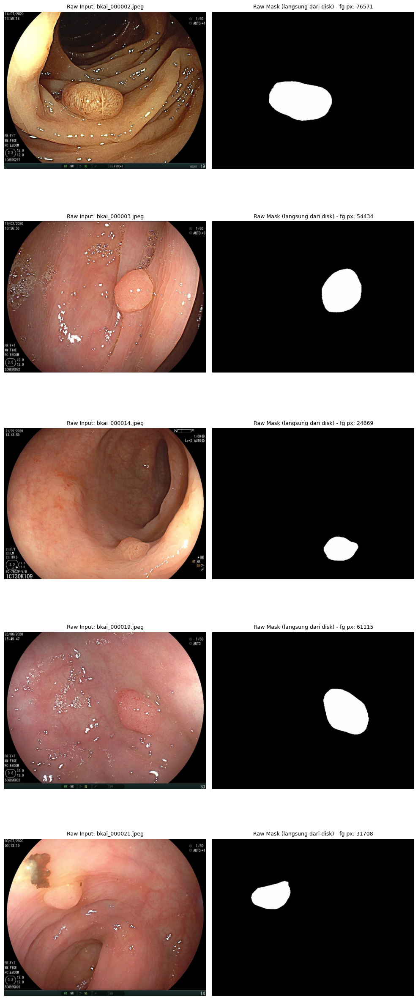


Diagnostic figure disimpan ke : /kaggle/working/raw_mask_diagnostic.png


In [13]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 13
# Single-Sample Deep Diagnostic (Raw Disk Read, Bypasses All Pipeline Code)
# =============================================================================
# Membaca 5 sampel test PERTAMA (sama persis dengan yang muncul di Prediction
# Visualization / Grad-CAM karena test_loader shuffle=False) langsung dari
# file di disk, tanpa resize/augmentasi/binarisasi apa pun, untuk memastikan
# secara pasti apakah masalahnya ada di file sumber atau di kode.
# =============================================================================

print("=" * 70)
print("SINGLE-SAMPLE DEEP DIAGNOSTIC (5 Sampel Test Pertama)")
print("=" * 70)

NUM_DIAGNOSTIC_SAMPLES = 5

fig, axes = plt.subplots(NUM_DIAGNOSTIC_SAMPLES, 2, figsize=(10, 5 * NUM_DIAGNOSTIC_SAMPLES))

if NUM_DIAGNOSTIC_SAMPLES == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(NUM_DIAGNOSTIC_SAMPLES):

    sample_image_path = test_dataset.image_files[i]
    sample_mask_path = test_dataset.mask_map.get(sample_image_path.stem)

    print(f"\n[{i}] Image : {sample_image_path.name}")
    print(f"    Mask  : {sample_mask_path.name if sample_mask_path else 'NOT FOUND'}")
    print(f"    Nama file (tanpa ekstensi) cocok : "
          f"{sample_image_path.stem == (sample_mask_path.stem if sample_mask_path else None)}")

    raw_image = cv2.cvtColor(cv2.imread(str(sample_image_path)), cv2.COLOR_BGR2RGB)
    raw_mask_unchanged = cv2.imread(str(sample_mask_path), cv2.IMREAD_UNCHANGED)

    channels = 1 if raw_mask_unchanged.ndim == 2 else raw_mask_unchanged.shape[2]
    mask_gray = raw_mask_unchanged.max(axis=2) if raw_mask_unchanged.ndim == 3 else raw_mask_unchanged

    nonzero_count = int((mask_gray > 127).sum())
    total_count = mask_gray.size

    print(f"    Mask shape (raw)       : {raw_mask_unchanged.shape} ({channels} channel(s))")
    print(f"    Mask value range (raw) : min={mask_gray.min()}, max={mask_gray.max()}")
    print(f"    Foreground pixels (>127): {nonzero_count} / {total_count} "
          f"({100*nonzero_count/total_count:.3f}%)")

    if nonzero_count == 0:
        print("    >>> KESIMPULAN: Mask ini KOSONG TOTAL langsung dari file di disk,")
        print("        SEBELUM melalui kode apa pun (resize/augmentasi/binarisasi).")
        print("        Ini adalah isu pada file anotasi sumber, bukan bug pipeline.")
    else:
        print("    >>> Mask ini punya anotasi valid di file mentah.")

    axes[i, 0].imshow(raw_image)
    axes[i, 0].set_title(f"Raw Input: {sample_image_path.name}", fontsize=9)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mask_gray, cmap="gray")
    axes[i, 1].set_title(f"Raw Mask (langsung dari disk) - fg px: {nonzero_count}", fontsize=9)
    axes[i, 1].axis("off")

plt.tight_layout()

diagnostic_path = OUTPUT_DIR / "raw_mask_diagnostic.png"
plt.savefig(diagnostic_path, dpi=150, bbox_inches="tight")
plt.show()

print("\n" + "=" * 70)
print(f"Diagnostic figure disimpan ke : {diagnostic_path}")
print("=" * 70)

# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 14
# Deteksi Otomatis Sumber Dataset untuk WeightedRandomSampler
# =============================================================================

In [14]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 14
# Deteksi Otomatis Sumber Dataset untuk WeightedRandomSampler
# =============================================================================

import re
from collections import Counter
from torch.utils.data import WeightedRandomSampler


def _extract_source_prefix(stem: str) -> str:
    """Strip trailing digits/separators to get a source-identifying prefix.
    Contoh: 'etis_015' -> 'etis', 'cvcclinicdb-042' -> 'cvcclinicdb'.
    """
    match = re.match(r"^(.*?)[\-_]?\d*$", stem)
    prefix = match.group(1) if match else stem
    prefix = prefix.lower().rstrip("-_")
    return prefix or stem.lower()


_train_stems = [p.stem for p in train_images]
_source_prefixes = [_extract_source_prefix(s) for s in _train_stems]
_prefix_counts = Counter(_source_prefixes)

print("=" * 70)
print("DETEKSI OTOMATIS SUMBER DATASET (berdasarkan pola nama file)")
print("=" * 70)

for prefix, count in _prefix_counts.most_common(15):
    example = next(s for s in _train_stems if _extract_source_prefix(s) == prefix)
    print(f"  '{prefix}': {count} citra  (contoh: {example})")

# Heuristik validasi: deteksi dianggap "berhasil" kalau jumlah grup masuk
# akal (2-10 grup) DAN grup terbesar tidak mendominasi >95% data (yang akan
# menandakan deteksi gagal / semua file kebetulan punya prefix serupa).
_num_source_groups = len(_prefix_counts)
_largest_group_share = max(_prefix_counts.values()) / len(_train_stems)

print("-" * 70)

if 2 <= _num_source_groups <= 10 and _largest_group_share < 0.95:

    _group_weight = {p: 1.0 / c for p, c in _prefix_counts.items()}
    _sample_weights = [_group_weight[p] for p in _source_prefixes]

    train_sampler = WeightedRandomSampler(
        weights=_sample_weights,
        num_samples=len(_sample_weights),
        replacement=True
    )

    print(f"BERHASIL: {_num_source_groups} kelompok sumber terdeteksi.")
    print("WeightedRandomSampler AKTIF -- tiap sumber akan mendapat porsi")
    print("lebih seimbang per epoch (sumber kecil di-upsample).")

else:
    train_sampler = None

    print(f"Deteksi TIDAK meyakinkan ({_num_source_groups} kelompok, kelompok")
    print(f"terbesar = {_largest_group_share*100:.1f}% dari data).")
    print("WeightedRandomSampler DINONAKTIFKAN -- training tetap memakai")
    print("shuffle acak biasa (aman, tidak ada perubahan perilaku).")
    print()
    print("Kalau nama file dataset Anda ternyata PUNYA pola sumber yang jelas")
    print("tapi tidak terdeteksi di atas, beri tahu contoh nama filenya --")
    print("regex _extract_source_prefix() bisa disesuaikan.")

print("=" * 70)

DETEKSI OTOMATIS SUMBER DATASET (berdasarkan pola nama file)
  'hyperpolyp': 809 citra  (contoh: hyperpolyp_000001)
  'kvasir': 801 citra  (contoh: kvasir_000003)
  'bkai': 794 citra  (contoh: bkai_000001)
  'clinicdb': 486 citra  (contoh: clinicdb_000002)
  'colondb': 303 citra  (contoh: colondb_000001)
  'etis': 149 citra  (contoh: etis_000001)
----------------------------------------------------------------------
BERHASIL: 6 kelompok sumber terdeteksi.
WeightedRandomSampler AKTIF -- tiap sumber akan mendapat porsi
lebih seimbang per epoch (sumber kecil di-upsample).


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 15
# Build DataLoader
# =============================================================================

In [15]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 15
# Build DataLoader
# =============================================================================

PIN_MEMORY = torch.cuda.is_available()
PERSISTENT_WORKERS = NUM_WORKERS > 0
PREFETCH_FACTOR = 2 if NUM_WORKERS > 0 else None

def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)
    torch.manual_seed(worker_seed)


generator = torch.Generator()
generator.manual_seed(SEED)

loader_kwargs = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker,
    generator=generator
)

if NUM_WORKERS > 0:
    loader_kwargs.update(
        persistent_workers=PERSISTENT_WORKERS,
        prefetch_factor=PREFETCH_FACTOR
    )

# REVISI (Version 13): pakai train_sampler (WeightedRandomSampler) kalau
# auto-deteksi sumber dataset berhasil (lihat cell sebelumnya); shuffle=True
# dan sampler tidak boleh dipakai bersamaan di PyTorch DataLoader.
if train_sampler is not None:
    train_loader = DataLoader(train_dataset, sampler=train_sampler, drop_last=True, **loader_kwargs)
else:
    train_loader = DataLoader(train_dataset, shuffle=True, drop_last=True, **loader_kwargs)

val_loader   = DataLoader(val_dataset, shuffle=False, drop_last=False, **loader_kwargs)
test_loader  = DataLoader(test_dataset, shuffle=False, drop_last=False, **loader_kwargs)

print("=" * 70)
print("DATALOADER SUMMARY")
print("=" * 70)

print(f"Batch Size         : {BATCH_SIZE}")
print(f"Num Workers        : {NUM_WORKERS}")
print(f"Pin Memory         : {PIN_MEMORY}")
print(f"Persistent Workers : {PERSISTENT_WORKERS}")
print(f"Train Sampling     : {'WeightedRandomSampler (source-balanced)' if train_sampler is not None else 'shuffle acak biasa'}")
print(f"Train Batch        : {len(train_loader)}")
print(f"Validation Batch   : {len(val_loader)}")
print(f"Test Batch         : {len(test_loader)}")

print("=" * 70)

DATALOADER SUMMARY
Batch Size         : 16
Num Workers        : 2
Pin Memory         : True
Persistent Workers : True
Train Sampling     : WeightedRandomSampler (source-balanced)
Train Batch        : 208
Validation Batch   : 27
Test Batch         : 27


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 16
# Dataset Sanity Check
# =============================================================================

TRAIN BATCH INFORMATION
Images Shape : torch.Size([16, 3, 512, 512])
Masks Shape  : torch.Size([16, 1, 512, 512])
Images Type  : torch.float32
Masks Type   : torch.float32
Mask Min     : 0
Mask Max     : 1


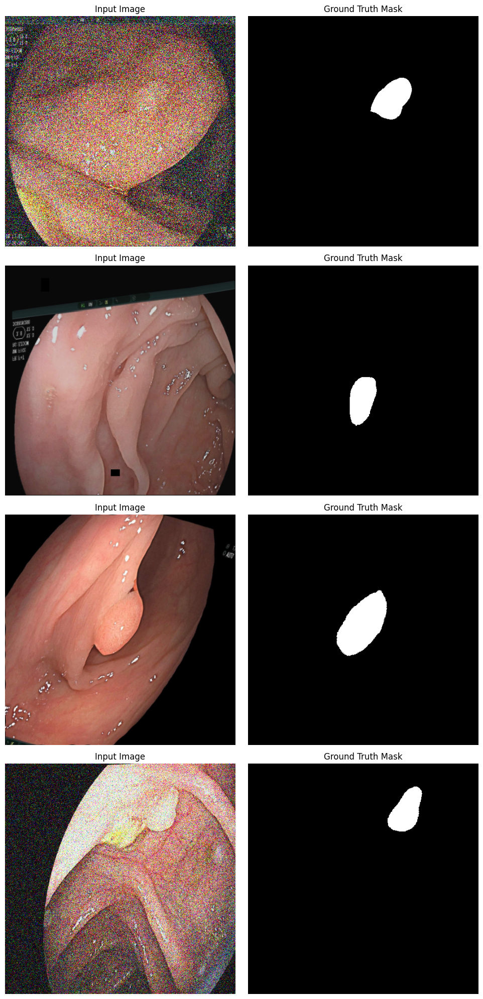

DATASET SANITY CHECK COMPLETED


In [16]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 16
# Dataset Sanity Check
# =============================================================================

def denormalize(image):
    """
    Convert normalized tensor back to RGB image.
    """

    image = image.detach().cpu().numpy().transpose(1, 2, 0)

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    image = image * std + mean
    image = np.clip(image, 0.0, 1.0)

    return image


images, masks = next(iter(train_loader))

print("=" * 70)
print("TRAIN BATCH INFORMATION")
print("=" * 70)

print(f"Images Shape : {images.shape}")
print(f"Masks Shape  : {masks.shape}")
print(f"Images Type  : {images.dtype}")
print(f"Masks Type   : {masks.dtype}")
print(f"Mask Min     : {masks.min().item():.0f}")
print(f"Mask Max     : {masks.max().item():.0f}")

print("=" * 70)

num_samples = min(4, images.size(0))

fig, axes = plt.subplots(num_samples, 2, figsize=(10, 5 * num_samples))

if num_samples == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(num_samples):

    image = denormalize(images[i])
    mask = masks[i, 0].cpu().numpy()

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Input Image")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground Truth Mask")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

print("=" * 70)
print("DATASET SANITY CHECK COMPLETED")
print("=" * 70)

# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 17
# Class Imbalance Analysis  (NEW)
# =============================================================================

In [17]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 17
# Class Imbalance Analysis  (NEW)
# =============================================================================
# Polyp area is typically a small fraction of the full image (class
# imbalance). We estimate the foreground/background pixel ratio from a random
# sample of training masks and use it to weight BCE via pos_weight, so the
# loss does not trivially favor predicting "background everywhere".
# =============================================================================

print("=" * 70)
print("CLASS IMBALANCE ANALYSIS")
print("=" * 70)

rng = random.Random(SEED)
sample_files = rng.sample(
    train_images,
    k=min(POS_WEIGHT_SAMPLE_SIZE, len(train_images))
)

total_fg = 0
total_px = 0

for image_path in tqdm(sample_files, desc="Scanning training masks"):

    mask_path = train_dataset.mask_map.get(image_path.stem)

    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    mask = (mask > 127).astype(np.uint8)

    total_fg += int(mask.sum())
    total_px += int(mask.size)

foreground_ratio = total_fg / total_px
background_ratio = 1.0 - foreground_ratio

raw_pos_weight = background_ratio / max(foreground_ratio, 1e-6)
pos_weight_value = float(np.clip(raw_pos_weight, POS_WEIGHT_MIN, POS_WEIGHT_MAX))

print(f"Sampled Masks       : {len(sample_files)}")
print(f"Foreground Pixels % : {foreground_ratio * 100:.3f}%")
print(f"Raw pos_weight      : {raw_pos_weight:.2f}")
print(f"Clipped pos_weight  : {pos_weight_value:.2f}  (range [{POS_WEIGHT_MIN}, {POS_WEIGHT_MAX}])")

print("=" * 70)

CLASS IMBALANCE ANALYSIS


Scanning training masks:   0%|          | 0/300 [00:00<?, ?it/s]

Sampled Masks       : 300
Foreground Pixels % : 5.928%
Raw pos_weight      : 15.87
Clipped pos_weight  : 15.87  (range [1.0, 20.0])


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 18
# Build Model
# =============================================================================

In [18]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 18
# Build Model
# =============================================================================

model = smp.Unet(
    encoder_name=ENCODER_NAME,
    encoder_weights=ENCODER_WEIGHTS,
    in_channels=IN_CHANNELS,
    classes=CLASSES,
    activation=None,
    decoder_attention_type=DECODER_ATTENTION
)

model = model.to(DEVICE)

# =============================================================================
# FREEZE ENCODER
# =============================================================================
if FREEZE_ENCODER:
    for param in model.encoder.parameters():
        param.requires_grad = False

# =============================================================================
# MODEL SUMMARY
# =============================================================================
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("=" * 70)
print("MODEL SUMMARY")
print("=" * 70)

print(f"Model              : {MODEL_NAME}")
print(f"Encoder            : {ENCODER_NAME}")
print(f"Encoder Weights    : {ENCODER_WEIGHTS}")
print(f"Decoder Attention  : {DECODER_ATTENTION}")

print("-" * 70)

print(f"Total Parameters   : {total_params:,}")
print(f"Trainable Params   : {trainable_params:,}")

print("=" * 70)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

MODEL SUMMARY
Model              : UNet
Encoder            : resnet50
Encoder Weights    : imagenet
Decoder Attention  : scse
----------------------------------------------------------------------
Total Parameters   : 33,816,076
Trainable Params   : 10,308,044


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 19
# Focal Tversky Loss + Combined Loss
# =============================================================================

In [19]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 19
# Focal Tversky Loss + Combined Loss
# =============================================================================

class FocalTverskyLoss(nn.Module):
    """
    Focal Tversky Loss (Abraham & Khan, 2019).
    alpha : penalty weight for False Positives.
    beta  : penalty weight for False Negatives.
    gamma : focusing parameter; gamma < 1 emphasizes hard / small lesions.
    """

    def __init__(self, alpha=0.30, beta=0.70, gamma=0.75, smooth=1e-6):
        super().__init__()
        self.alpha = alpha
        self.beta = beta
        self.gamma = gamma
        self.smooth = smooth

    def forward(self, logits, targets):

        probs = torch.sigmoid(logits)

        probs = probs.reshape(probs.size(0), -1)
        targets = targets.reshape(targets.size(0), -1)

        tp = (probs * targets).sum(dim=1)
        fp = ((1.0 - targets) * probs).sum(dim=1)
        fn = (targets * (1.0 - probs)).sum(dim=1)

        tversky = (tp + self.smooth) / (
            tp + self.alpha * fp + self.beta * fn + self.smooth
        )

        focal_tversky = (1.0 - tversky).pow(self.gamma)

        return focal_tversky.mean()


# =============================================================================
# LOVASZ-HINGE LOSS (Berman, Triki & Blaschko, 2018) -- BARU (Version 18)
# =============================================================================
# Surrogate cembung-per-bagian yang DIFERENSIABEL LANGSUNG untuk IoU/Jaccard
# index -- bukan proxy tidak langsung seperti Dice/BCE. Dipilih secara
# spesifik karena target penelitian menyebutkan IoU>95 secara eksplisit.
# Implementasi mengikuti referensi resmi penulis paper (per-image, binary).
# =============================================================================

def _lovasz_grad(gt_sorted):
    """Gradien dari Lovasz extension terhadap error yang sudah diurutkan."""
    p = len(gt_sorted)
    gts = gt_sorted.sum()
    intersection = gts - gt_sorted.float().cumsum(0)
    union = gts + (1.0 - gt_sorted).float().cumsum(0)
    jaccard = 1.0 - intersection / union
    if p > 1:
        jaccard[1:p] = jaccard[1:p] - jaccard[0:-1]
    return jaccard


def _lovasz_hinge_flat(logits, labels):
    """
    logits: [P] -- nilai logit mentah (rentang bebas, TANPA sigmoid)
    labels: [P] -- label biner ground truth (0 atau 1)
    """
    if labels.numel() == 0:
        return logits.sum() * 0.0

    signs = 2.0 * labels.float() - 1.0
    errors = 1.0 - logits * signs
    errors_sorted, perm = torch.sort(errors, dim=0, descending=True)
    gt_sorted = labels[perm]
    grad = _lovasz_grad(gt_sorted)

    loss = torch.dot(F.relu(errors_sorted), grad)

    return loss


class LovaszHingeLoss(nn.Module):
    """
    Lovasz-Hinge loss untuk segmentasi biner, dihitung PER CITRA lalu
    dirata-rata dalam satu batch (standar sesuai paper aslinya -- IoU
    dihitung secara natural per citra, bukan digabung dulu di level batch).
    """

    def forward(self, logits, targets):

        batch_size = logits.size(0)
        losses = []

        for i in range(batch_size):
            flat_logits = logits[i].reshape(-1)
            flat_targets = targets[i].reshape(-1)
            losses.append(_lovasz_hinge_flat(flat_logits, flat_targets))

        return torch.stack(losses).mean()


class BoundaryLoss(nn.Module):
    """
    Simplified boundary loss (Kervadec et al., 2019), based on a signed
    distance transform of the ground truth mask. Positive outside the
    foreground region, negative inside. Multiplying by predicted
    probabilities and averaging encourages predictions to align precisely
    with the true boundary, directly targeting the kind of error HD95
    measures (not just overall overlap area like Dice/IoU/Tversky do).

    DIMATIKAN PERMANEN sejak Version 15 (lihat USE_BOUNDARY_LOSS di Global
    Configuration) -- class ini dipertahankan hanya untuk kompatibilitas
    kalau ingin diaktifkan kembali untuk eksperimen terpisah.
    """

    @staticmethod
    def _compute_sdf_batch(gt_masks: torch.Tensor) -> torch.Tensor:

        gt_np = gt_masks.detach().cpu().numpy()
        sdf_batch = np.zeros_like(gt_np, dtype=np.float32)

        for i in range(gt_np.shape[0]):

            mask = gt_np[i, 0].astype(np.uint8)

            if mask.max() == 0:
                sdf_batch[i, 0] = np.ones_like(mask, dtype=np.float32)
                continue

            if mask.min() == 1:
                sdf_batch[i, 0] = -np.ones_like(mask, dtype=np.float32)
                continue

            dist_outside = cv2.distanceTransform(1 - mask, cv2.DIST_L2, 5)
            dist_inside = cv2.distanceTransform(mask, cv2.DIST_L2, 5)

            sdf = dist_outside - dist_inside
            max_abs = max(float(sdf.max()), float(-sdf.min()), 1e-6)
            sdf_batch[i, 0] = (sdf / max_abs).astype(np.float32)

        return torch.from_numpy(sdf_batch)

    def forward(self, logits, targets):

        probs = torch.sigmoid(logits)

        with torch.no_grad():
            sdf = self._compute_sdf_batch(targets).to(logits.device)

        return (probs * sdf).mean()


class CombinedLoss(nn.Module):
    """
    Weighted combination of class-imbalance-aware BCE, Dice, Focal Tversky,
    Lovasz-Hinge (BARU, Version 18), dan (opsional) Boundary loss.
    """

    def __init__(
        self,
        bce_weight=BCE_WEIGHT,
        dice_weight=DICE_WEIGHT,
        tversky_weight=TVERSKY_WEIGHT,
        lovasz_weight=LOVASZ_WEIGHT,
        alpha=TVERSKY_ALPHA,
        beta=TVERSKY_BETA,
        gamma=FOCAL_TVERSKY_GAMMA,
        pos_weight=None,
        use_boundary_loss=USE_BOUNDARY_LOSS,
        boundary_weight=BOUNDARY_LOSS_WEIGHT
    ):
        super().__init__()

        self.bce_weight = bce_weight
        self.dice_weight = dice_weight
        self.tversky_weight = tversky_weight
        self.lovasz_weight = lovasz_weight
        self.use_boundary_loss = use_boundary_loss
        self.boundary_weight = boundary_weight

        if pos_weight is not None:
            self.bce_loss = nn.BCEWithLogitsLoss(
                pos_weight=torch.tensor([pos_weight], device=DEVICE)
            )
        else:
            self.bce_loss = nn.BCEWithLogitsLoss()

        self.dice_loss = smp.losses.DiceLoss(mode="binary", from_logits=True)

        self.tversky_loss = FocalTverskyLoss(alpha=alpha, beta=beta, gamma=gamma)

        self.lovasz_loss = LovaszHingeLoss()

        if self.use_boundary_loss:
            self.boundary_loss = BoundaryLoss()

    def forward(self, prediction, target):

        bce = self.bce_loss(prediction, target)
        dice = self.dice_loss(prediction, target)
        tversky = self.tversky_loss(prediction, target)
        lovasz = self.lovasz_loss(prediction, target)

        loss = (
            self.bce_weight * bce +
            self.dice_weight * dice +
            self.tversky_weight * tversky +
            self.lovasz_weight * lovasz
        )

        if self.use_boundary_loss:
            loss = loss + self.boundary_weight * self.boundary_loss(prediction, target)

        return loss


criterion = CombinedLoss(pos_weight=pos_weight_value)

print("=" * 70)
print("LOSS FUNCTION")
print("=" * 70)
print(f"{BCE_WEIGHT*100:.0f}% BCEWithLogitsLoss (pos_weight={pos_weight_value:.2f})")
print(f"{DICE_WEIGHT*100:.0f}% Dice Loss")
print(f"{TVERSKY_WEIGHT*100:.0f}% Focal Tversky Loss "
      f"(alpha={TVERSKY_ALPHA}, beta={TVERSKY_BETA}, gamma={FOCAL_TVERSKY_GAMMA})")
print(f"{LOVASZ_WEIGHT*100:.0f}% Lovasz-Hinge Loss (surrogate langsung untuk IoU/Jaccard)")
print("Recall diprioritaskan (beta > alpha) sesuai justifikasi medis proposal.")
if USE_BOUNDARY_LOSS:
    print(f"+ Boundary Loss AKTIF (weight={BOUNDARY_LOSS_WEIGHT}) -- targetkan presisi HD95.")
    print("  PERINGATAN: ini konfigurasi belum tervalidasi, training dari awal.")
else:
    print("Boundary Loss TIDAK AKTIF (dimatikan permanen sejak Version 15 -- terbukti")
    print("jadi bottleneck CPU tanpa manfaat HD95 yang jelas).")
print("=" * 70)

LOSS FUNCTION
10% BCEWithLogitsLoss (pos_weight=15.87)
40% Dice Loss
35% Focal Tversky Loss (alpha=0.3, beta=0.7, gamma=0.75)
15% Lovasz-Hinge Loss (surrogate langsung untuk IoU/Jaccard)
Recall diprioritaskan (beta > alpha) sesuai justifikasi medis proposal.
Boundary Loss TIDAK AKTIF (dimatikan permanen sejak Version 15 -- terbukti
jadi bottleneck CPU tanpa manfaat HD95 yang jelas).


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 20
# Optimizer, Warmup + Cosine Annealing Scheduler & AMP
# =============================================================================

In [20]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 20
# Optimizer, Warmup + Cosine Annealing Scheduler & AMP
# =============================================================================
# Differential learning rate: encoder gets a smaller LR than the decoder /
# segmentation head once unfrozen, since the encoder already carries useful
# ImageNet features and only needs gentle fine-tuning.
# =============================================================================

encoder_params = list(model.encoder.parameters())
decoder_params = (
    list(model.decoder.parameters()) +
    list(model.segmentation_head.parameters())
)

optimizer = optim.AdamW(
    [
        {
            "params": encoder_params,
            "lr": LEARNING_RATE * ENCODER_LR_MULTIPLIER,
            "name": "encoder"
        },
        {
            "params": decoder_params,
            "lr": LEARNING_RATE,
            "name": "decoder"
        }
    ],
    weight_decay=WEIGHT_DECAY
)

warmup_scheduler = optim.lr_scheduler.LinearLR(
    optimizer,
    start_factor=0.1,
    total_iters=WARMUP_EPOCHS
)

cosine_scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=max(NUM_EPOCHS - WARMUP_EPOCHS, 1),
    eta_min=1e-6
)

scheduler = optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[warmup_scheduler, cosine_scheduler],
    milestones=[WARMUP_EPOCHS]
)

scaler = GradScaler(enabled=USE_AMP)

print("=" * 70)
print("TRAINING CONFIGURATION")
print("=" * 70)

print("Optimizer          : AdamW (differential LR: encoder / decoder)")
print(f"Base Learning Rate : {LEARNING_RATE}")
print(f"Encoder LR         : {LEARNING_RATE * ENCODER_LR_MULTIPLIER}")
print(f"Weight Decay       : {WEIGHT_DECAY}")
print(f"Scheduler          : LinearLR warmup ({WARMUP_EPOCHS} epochs) -> CosineAnnealingLR")
print(f"Mixed Precision    : {USE_AMP}")

print("=" * 70)

TRAINING CONFIGURATION
Optimizer          : AdamW (differential LR: encoder / decoder)
Base Learning Rate : 0.0001
Encoder LR         : 2.5e-05
Weight Decay       : 0.0001
Scheduler          : LinearLR warmup (3 epochs) -> CosineAnnealingLR
Mixed Precision    : True


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 21
# Evaluation Metrics
# =============================================================================

In [21]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 21
# Evaluation Metrics
# =============================================================================
# dice_score / iou_score accept either raw logits (from_logits=True, default,
# used during training/validation) or already-averaged TTA probabilities
# (from_logits=False, used during final evaluation / threshold search).
# =============================================================================

def dice_score(outputs, targets, threshold: float = 0.5, eps: float = 1e-7,
               from_logits: bool = True):

    probs = torch.sigmoid(outputs) if from_logits else outputs
    preds = (probs > threshold).float()
    targets = targets.float()

    intersection = (preds * targets).sum(dim=(1, 2, 3))
    union = preds.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))

    dice = (2.0 * intersection + eps) / (union + eps)

    return dice.mean()


def iou_score(outputs, targets, threshold: float = 0.5, eps: float = 1e-7,
              from_logits: bool = True):

    probs = torch.sigmoid(outputs) if from_logits else outputs
    preds = (probs > threshold).float()
    targets = targets.float()

    intersection = (preds * targets).sum(dim=(1, 2, 3))
    union = (
        preds.sum(dim=(1, 2, 3)) +
        targets.sum(dim=(1, 2, 3)) -
        intersection
    )

    iou = (intersection + eps) / (union + eps)

    return iou.mean()


accuracy_metric = BinaryAccuracy().to(DEVICE)
precision_metric = BinaryPrecision().to(DEVICE)
recall_metric = BinaryRecall().to(DEVICE)

print("=" * 70)
print("EVALUATION METRICS READY")
print("=" * 70)
print("dice_score(outputs, targets, threshold=0.5, from_logits=True)")
print("iou_score(outputs, targets, threshold=0.5, from_logits=True)")
print("accuracy_metric / precision_metric / recall_metric ready")
print("=" * 70)

EVALUATION METRICS READY
dice_score(outputs, targets, threshold=0.5, from_logits=True)
iou_score(outputs, targets, threshold=0.5, from_logits=True)
accuracy_metric / precision_metric / recall_metric ready


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 22
# Exponential Moving Average (EMA) of Model Weights
# =============================================================================

In [22]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 22
# Exponential Moving Average (EMA) of Model Weights
# =============================================================================
# ema_model is a shadow copy of `model` whose weights are a decayed running
# average of the training weights. EMA weights are what gets validated,
# checkpointed as "best model", and therefore what everything downstream
# (threshold search, Grad-CAM, deployment) ultimately uses.
# =============================================================================

class ModelEMA:

    def __init__(self, model, decay=0.999):

        self.ema_model = copy.deepcopy(model).to(DEVICE)
        self.ema_model.eval()

        for param in self.ema_model.parameters():
            param.requires_grad_(False)

        self.decay = decay

    @torch.no_grad()
    def update(self, model):

        ema_state = self.ema_model.state_dict()
        model_state = model.state_dict()

        for key, ema_value in ema_state.items():

            model_value = model_state[key].detach()

            if ema_value.dtype.is_floating_point:
                ema_value.copy_(
                    ema_value * self.decay + model_value * (1.0 - self.decay)
                )
            else:
                ema_value.copy_(model_value)


ema_tracker = ModelEMA(model, decay=EMA_DECAY) if USE_EMA else None
ema_model = ema_tracker.ema_model if USE_EMA else model

print("=" * 70)
print("EMA TRACKER READY" if USE_EMA else "EMA DISABLED (ema_model == model)")
print("=" * 70)

EMA TRACKER READY


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 23
# Post-Processing & Test-Time Augmentation Utilities
# =============================================================================

In [23]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 23
# Post-Processing & Test-Time Augmentation Utilities
# =============================================================================

def smooth_contours(binary_mask: np.ndarray,
                     epsilon_ratio: float = CONTOUR_SMOOTHING_EPSILON_RATIO) -> np.ndarray:
    """
    Light contour regularization (Version 7). Morphological open/close
    operates pixel-by-pixel and can leave small "staircase" jaggedness along
    the boundary. cv2.approxPolyDP simplifies each contour's polygon with a
    small epsilon (proportional to perimeter), smoothing out that pixel-level
    noise without altering genuine shape/size. This does NOT require
    retraining -- it only changes how an already-predicted mask is cleaned up.
    """

    mask = binary_mask.astype(np.uint8)

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if not contours:
        return mask

    smoothed = np.zeros_like(mask)

    for contour in contours:
        perimeter = cv2.arcLength(contour, True)
        if perimeter == 0:
            continue
        epsilon = epsilon_ratio * perimeter
        approx = cv2.approxPolyDP(contour, epsilon, True)
        cv2.drawContours(smoothed, [approx], -1, color=1, thickness=cv2.FILLED)

    return smoothed


def postprocess_mask(binary_mask: np.ndarray,
                      min_area: int = POST_PROCESS_MIN_AREA,
                      kernel_size: int = POST_PROCESS_KERNEL_SIZE,
                      use_contour_smoothing: bool = USE_CONTOUR_SMOOTHING) -> np.ndarray:
    """
    Remove small noisy blobs, close small holes, and (optionally) smooth
    jagged boundaries in a predicted binary mask. Operates on a single 2D
    (H, W) uint8 mask with values in {0, 1}.
    """

    mask = binary_mask.astype(np.uint8)
    kernel = np.ones((kernel_size, kernel_size), np.uint8)

    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        mask, connectivity=8
    )

    cleaned = np.zeros_like(mask)

    for label_id in range(1, num_labels):
        if stats[label_id, cv2.CC_STAT_AREA] >= min_area:
            cleaned[labels == label_id] = 1

    # REVISI (Version 13): tutup lubang internal (mis. area tengah polip yang
    # terlewat karena specular reflection/tekstur) yang tidak tertutup oleh
    # MORPH_CLOSE kernel kecil di atas -- menaikkan Dice/IoU pada prediksi
    # yang bentuknya sudah benar tapi berlubang di dalamnya.
    if cleaned.sum() > 0:
        cleaned = binary_fill_holes(cleaned).astype(np.uint8)

    if use_contour_smoothing and cleaned.sum() > 0:
        cleaned = smooth_contours(cleaned)

    return cleaned


def postprocess_batch(preds_np: np.ndarray) -> np.ndarray:
    """
    Apply postprocess_mask() to every sample in a (B, 1, H, W) numpy batch.
    """

    cleaned_batch = np.zeros_like(preds_np)

    for i in range(preds_np.shape[0]):
        cleaned_batch[i, 0] = postprocess_mask(preds_np[i, 0])

    return cleaned_batch


@torch.no_grad()
def _predict_single_scale(model, images, use_tta: bool, target_h: int, target_w: int):
    """
    Run flip+rotation TTA (optional) at the resolution `images` already has,
    then resize the resulting probability map(s) back to (target_h, target_w).
    REVISI (Version 17): 3-way (original+H-flip+V-flip) -> 5-way, menambah
    rotasi 90deg dan 270deg. Citra input persegi (512x512) sehingga rotasi
    90/270deg tidak mengubah dimensi -- aman untuk stride-32 ResNet50. Ini
    murni tambahan di sisi inferensi (tidak menyentuh training), sedikit
    menambah biaya komputasi evaluasi untuk potensi Dice/IoU sedikit lebih
    tinggi lewat averaging orientasi yang lebih beragam.
    """

    def _resize_if_needed(probs):
        if probs.shape[-2:] != (target_h, target_w):
            probs = F.interpolate(
                probs, size=(target_h, target_w),
                mode="bilinear", align_corners=False
            )
        return probs

    logits = model(images)
    probs_list = [_resize_if_needed(torch.sigmoid(logits))]

    if use_tta:
        h_flipped = torch.flip(images, dims=[3])
        h_logits = model(h_flipped)
        h_probs = torch.flip(torch.sigmoid(h_logits), dims=[3])
        probs_list.append(_resize_if_needed(h_probs))

        v_flipped = torch.flip(images, dims=[2])
        v_logits = model(v_flipped)
        v_probs = torch.flip(torch.sigmoid(v_logits), dims=[2])
        probs_list.append(_resize_if_needed(v_probs))

        rot90_images = torch.rot90(images, k=1, dims=[2, 3])
        rot90_logits = model(rot90_images)
        rot90_probs = torch.rot90(torch.sigmoid(rot90_logits), k=-1, dims=[2, 3])
        probs_list.append(_resize_if_needed(rot90_probs))

        rot270_images = torch.rot90(images, k=3, dims=[2, 3])
        rot270_logits = model(rot270_images)
        rot270_probs = torch.rot90(torch.sigmoid(rot270_logits), k=-3, dims=[2, 3])
        probs_list.append(_resize_if_needed(rot270_probs))

    return probs_list


@torch.no_grad()
def predict_with_tta(model, images, use_tta: bool = True,
                      use_multiscale: bool = USE_MULTISCALE_TTA,
                      scales=MULTISCALE_TTA_SCALES):
    """
    Returns averaged sigmoid probabilities (NOT logits).
    Combines flip+rotation TTA (original + H-flip + V-flip + rot90 + rot270,
    5-way) with optional multi-scale TTA (inference at multiple resolutions,
    resized back and averaged). Scale sizes are rounded to the nearest
    multiple of 32 to stay safe with ResNet50's stride-32 downsampling.
    """

    target_h, target_w = images.shape[-2], images.shape[-1]

    scale_list = list(scales) if use_multiscale else [1.0]

    all_probs = []

    for scale in scale_list:

        if scale == 1.0:
            scaled_images = images
        else:
            new_h = max(32, int(round(target_h * scale / 32)) * 32)
            new_w = max(32, int(round(target_w * scale / 32)) * 32)
            scaled_images = F.interpolate(
                images, size=(new_h, new_w),
                mode="bilinear", align_corners=False
            )

        all_probs.extend(
            _predict_single_scale(model, scaled_images, use_tta, target_h, target_w)
        )

    return torch.stack(all_probs, dim=0).mean(dim=0)

print("=" * 70)
print("POST-PROCESSING & TTA UTILITIES READY")
print("=" * 70)

POST-PROCESSING & TTA UTILITIES READY


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 24
# Training Utilities & Resume From Checkpoint
# =============================================================================

In [24]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 24
# Training Utilities & Resume From Checkpoint
# =============================================================================

RESUME_TRAINING = True

# Biarkan seperti ini (CHECKPOINT_PATH) untuk melanjutkan training di dalam
# SESSION YANG SAMA setelah koneksi sempat putus. Ganti ke path dataset input
# yang dilampirkan (mis. "/kaggle/input/pixelt-checkpoint/pixelt_checkpoint.pth")
# untuk melanjutkan training di SESSION BARU setelah session lama benar-benar
# berakhir.
RESUME_CHECKPOINT_PATH = CHECKPOINT_PATH

history = {
    "train_loss": [],
    "val_loss": [],
    "train_dice": [],
    "val_dice": [],
    "train_iou": [],
    "val_iou": [],
    "learning_rate_encoder": [],
    "learning_rate_decoder": []
}

best_epoch = 0
best_dice = 0.0
best_threshold = BEST_THRESHOLD

early_stopping_counter = 0

start_epoch = 1
encoder_unfrozen = not FREEZE_ENCODER

if RESUME_TRAINING and Path(RESUME_CHECKPOINT_PATH).exists():

    print("=" * 70)
    print("CHECKPOINT DITEMUKAN -- MELANJUTKAN TRAINING")
    print("=" * 70)

    checkpoint = torch.load(RESUME_CHECKPOINT_PATH, map_location=DEVICE)

    # ==================================================================
    # RESTORE MODEL WEIGHTS
    # ==================================================================
    model.load_state_dict(checkpoint["model_state_dict"])

    if USE_EMA and "ema_state_dict" in checkpoint:
        ema_model.load_state_dict(checkpoint["ema_state_dict"])

    # ==================================================================
    # RESTORE OPTIMIZER / SCHEDULER / AMP SCALER STATE
    # ==================================================================
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    # REVISI (Version 10): scheduler_state_dict HANYA di-load mentah-mentah
    # jika NUM_EPOCHS belum berubah sejak checkpoint dibuat. CosineAnnealingLR
    # menyimpan T_max di dalam state-nya -- kalau NUM_EPOCHS berubah (mis.
    # 120 -> 180 seperti revisi ini), me-load state lama akan membuat
    # scheduler baru (yang sudah dibangun dengan T_max sesuai NUM_EPOCHS=180)
    # justru memakai T_max=117 yang usang, sehingga LR turun ke eta_min jauh
    # lebih awal dari yang seharusnya. Sebagai gantinya, scheduler yang baru
    # (T_max sudah benar) di-"fast-forward" dengan memanggil .step() sebanyak
    # epoch yang sudah dilalui.
    _checkpoint_num_epochs = checkpoint.get("num_epochs_configured", NUM_EPOCHS)

    if _checkpoint_num_epochs == NUM_EPOCHS:
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    else:
        print(
            f"PERINGATAN: NUM_EPOCHS berubah ({_checkpoint_num_epochs} -> "
            f"{NUM_EPOCHS}) sejak checkpoint ini dibuat. Scheduler DIBANGUN "
            f"ULANG dengan T_max baru dan di-fast-forward ke epoch "
            f"{checkpoint['epoch']}, BUKAN memuat state lama."
        )
        for _ in range(checkpoint["epoch"]):
            scheduler.step()

    if USE_AMP and "scaler_state_dict" in checkpoint:
        scaler.load_state_dict(checkpoint["scaler_state_dict"])

    # ==================================================================
    # RESTORE TRAINING PROGRESS
    # ==================================================================
    history = checkpoint.get("history", history)
    best_dice = checkpoint.get("best_dice", 0.0)
    best_epoch = checkpoint.get("best_epoch", 0)
    encoder_unfrozen = checkpoint.get("encoder_unfrozen", not FREEZE_ENCODER)

    start_epoch = checkpoint["epoch"] + 1

    # Make sure encoder requires_grad matches the point of interruption
    if encoder_unfrozen:
        for param in model.encoder.parameters():
            param.requires_grad = True

    print(f"Resuming from epoch : {start_epoch}")
    print(f"Best Dice so far    : {best_dice:.4f} (Epoch {best_epoch})")
    print(f"Encoder unfrozen    : {encoder_unfrozen}")

else:
    print("=" * 70)
    print("TIDAK ADA CHECKPOINT -- MEMULAI TRAINING BARU")
    print("=" * 70)

print(f"Start Epoch          : {start_epoch}")
print(f"Best Dice            : {best_dice:.4f}")
print(f"Best Threshold       : {best_threshold:.2f}")
print(f"Early Stopping       : {EARLY_STOPPING_PATIENCE}")

print("=" * 70)

TIDAK ADA CHECKPOINT -- MEMULAI TRAINING BARU
Start Epoch          : 1
Best Dice            : 0.0000
Best Threshold       : 0.50
Early Stopping       : 18


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 25
# Training Function
# =============================================================================

In [25]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 25
# Training Function
# =============================================================================
# EMA weights are updated after every optimizer step (once the underlying
# parameters have actually been modified by scaler.step()).
#
# REVISI (Version 16): tambah NaN/Inf loss guard -- kalau satu batch
# menghasilkan loss NaN/Inf (bisa terjadi sesekali akibat kombinasi AMP +
# custom loss seperti Tversky pada kasus tepi tertentu), batch tsb DILEWATI
# (optimizer.step() TIDAK dipanggil) alih-alih membiarkan NaN merambat ke
# bobot model dan merusak seluruh training yang sudah berjalan. Jumlah batch
# yang dilewati dilaporkan di akhir epoch sebagai sinyal diagnostik -- kalau
# angkanya lebih dari sesekali, itu tanda perlu investigasi lebih lanjut
# (bukan sekadar "aman diabaikan").
# =============================================================================

def train_one_epoch(model, loader, optimizer, criterion, scaler, device,
                     ema_tracker=None):

    model.train()

    running_loss = 0.0
    running_dice = 0.0
    running_iou = 0.0
    skipped_batches = 0

    progress_bar = tqdm(loader, desc="Training", leave=False)

    for images, masks in progress_bar:

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with autocast(enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, masks)

        if not torch.isfinite(loss):
            skipped_batches += 1
            progress_bar.set_postfix(Loss="SKIP (NaN/Inf)", Dice="--")
            continue

        scaler.scale(loss).backward()

        if USE_GRADIENT_CLIPPING:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_VALUE)

        scaler.step(optimizer)
        scaler.update()

        if ema_tracker is not None:
            ema_tracker.update(model)

        with torch.no_grad():
            dice = dice_score(outputs, masks)
            iou = iou_score(outputs, masks)

        running_loss += loss.item()
        running_dice += dice.item()
        running_iou += iou.item()

        progress_bar.set_postfix(
            Loss=f"{loss.item():.4f}",
            Dice=f"{dice.item():.4f}"
        )

    num_valid_batches = max(len(loader) - skipped_batches, 1)

    epoch_loss = running_loss / num_valid_batches
    epoch_dice = running_dice / num_valid_batches
    epoch_iou = running_iou / num_valid_batches

    if skipped_batches > 0:
        print(f"PERINGATAN: {skipped_batches}/{len(loader)} batch dilewati "
              f"di epoch ini karena loss NaN/Inf.")

    return epoch_loss, epoch_dice, epoch_iou

print("train_one_epoch() defined (dengan NaN/Inf loss guard).")

train_one_epoch() defined (dengan NaN/Inf loss guard).


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 26
# Validation Function
# =============================================================================

In [26]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 26
# Validation Function
# =============================================================================
# Validation is run on the model passed in explicitly -- during training this
# will be `ema_model` (see Training Loop), so the metric used for best-model
# selection / early stopping reflects the EMA weights.
# =============================================================================

@torch.no_grad()
def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    running_dice = 0.0
    running_iou = 0.0

    progress_bar = tqdm(loader, desc="Validation", leave=False)

    for images, masks in progress_bar:

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        with autocast(enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, masks)

        dice = dice_score(outputs, masks)
        iou = iou_score(outputs, masks)

        running_loss += loss.item()
        running_dice += dice.item()
        running_iou += iou.item()

        progress_bar.set_postfix(
            Loss=f"{loss.item():.4f}",
            Dice=f"{dice.item():.4f}"
        )

    epoch_loss = running_loss / len(loader)
    epoch_dice = running_dice / len(loader)
    epoch_iou = running_iou / len(loader)

    return epoch_loss, epoch_dice, epoch_iou

print("validate_one_epoch() defined.")

validate_one_epoch() defined.


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 27
# Encoder Freeze Strategy
# =============================================================================

In [27]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 27
# Encoder Freeze Strategy
# =============================================================================

encoder_unfrozen = not FREEZE_ENCODER

def unfreeze_encoder(model):
    """
    Unfreeze encoder parameters. The differential LR set up in the optimizer
    (Cell 15) already applies a smaller LR to these parameters.
    """

    for param in model.encoder.parameters():
        param.requires_grad = True

    print("=" * 70)
    print("ENCODER UNFROZEN")
    print("=" * 70)
    print(f"Fine-tuning starts from epoch {UNFREEZE_EPOCH}")
    print(f"Encoder LR : {LEARNING_RATE * ENCODER_LR_MULTIPLIER}")
    print("=" * 70)

print("Encoder freeze strategy ready.")

Encoder freeze strategy ready.


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 28
# Training Loop
# =============================================================================

In [28]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 28
# Training Loop
# =============================================================================
# Structural bug from the previous draft remains fixed here: best-model
# tracking, checkpointing, and early stopping are genuinely INSIDE the
# per-epoch loop body. Validation, best-model selection, and checkpointing
# are all based on `ema_model` when USE_EMA is True.
# =============================================================================

print("=" * 70)
print("START TRAINING")
print("=" * 70)

training_start_time = time.time()

for epoch in range(start_epoch, NUM_EPOCHS + 1):

    print(f"\nEpoch [{epoch}/{NUM_EPOCHS}]")
    print("-" * 70)

    # ==================================================================
    # UNFREEZE ENCODER
    # ==================================================================
    if FREEZE_ENCODER and not encoder_unfrozen and epoch == UNFREEZE_EPOCH:
        unfreeze_encoder(model)
        encoder_unfrozen = True

    # ==================================================================
    # TRAIN
    # ==================================================================
    train_loss, train_dice, train_iou = train_one_epoch(
        model=model,
        loader=train_loader,
        optimizer=optimizer,
        criterion=criterion,
        scaler=scaler,
        device=DEVICE,
        ema_tracker=ema_tracker
    )

    # ==================================================================
    # VALIDATION (on EMA weights when enabled)
    # ==================================================================
    val_loss, val_dice, val_iou = validate_one_epoch(
        model=ema_model,
        loader=val_loader,
        criterion=criterion,
        device=DEVICE
    )

    # ==================================================================
    # SCHEDULER
    # ==================================================================
    scheduler.step()

    current_lr_encoder = optimizer.param_groups[0]["lr"]
    current_lr_decoder = optimizer.param_groups[1]["lr"]

    # ==================================================================
    # SAVE HISTORY
    # ==================================================================
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_dice"].append(train_dice)
    history["val_dice"].append(val_dice)
    history["train_iou"].append(train_iou)
    history["val_iou"].append(val_iou)
    history["learning_rate_encoder"].append(current_lr_encoder)
    history["learning_rate_decoder"].append(current_lr_decoder)

    # ==================================================================
    # SHOW RESULT
    # ==================================================================
    print(
        f"Train Loss : {train_loss:.4f} | "
        f"Train Dice : {train_dice:.4f} | "
        f"Train IoU : {train_iou:.4f}"
    )
    print(
        f"Val Loss (EMA) : {val_loss:.4f} | "
        f"Val Dice (EMA) : {val_dice:.4f} | "
        f"Val IoU (EMA)  : {val_iou:.4f}"
    )
    print(f"LR Encoder : {current_lr_encoder:.8f} | LR Decoder : {current_lr_decoder:.8f}")

    # ==================================================================
    # BEST MODEL (based on EMA validation Dice, checked every epoch)
    # ==================================================================
    if val_dice > best_dice:

        best_dice = val_dice
        best_epoch = epoch

        # Atomic write: save to a temp file first, then rename. This avoids
        # a half-written / corrupted best_model.pth if the process gets
        # interrupted exactly during the save.
        temp_model_path = (OUTPUT_DIR / MODEL_SAVE_NAME).with_suffix(".tmp")
        torch.save(ema_model.state_dict(), temp_model_path)
        os.replace(temp_model_path, OUTPUT_DIR / MODEL_SAVE_NAME)

        early_stopping_counter = 0

        print(">>> Best Model Updated (EMA weights saved)")

    else:
        early_stopping_counter += 1

    print(f"Best Dice : {best_dice:.4f} (Epoch {best_epoch})")

    # ==================================================================
    # SAVE CHECKPOINT (every epoch)
    # ==================================================================
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "ema_state_dict": ema_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "num_epochs_configured": NUM_EPOCHS,  # (Version 10) untuk deteksi
                                                # mismatch scheduler saat resume
        "history": history,
        "best_dice": best_dice,
        "best_epoch": best_epoch,
        "encoder_unfrozen": encoder_unfrozen
    }

    if USE_AMP:
        checkpoint["scaler_state_dict"] = scaler.state_dict()

    # Atomic write for the same reason as best_model.pth above.
    temp_checkpoint_path = CHECKPOINT_PATH.with_suffix(".tmp")
    torch.save(checkpoint, temp_checkpoint_path)
    os.replace(temp_checkpoint_path, CHECKPOINT_PATH)
    print(f">>> Checkpoint Saved : Epoch {epoch}")

    # ==================================================================
    # BACKUP CHECKPOINT (every BACKUP_INTERVAL epochs, auto-pruned)
    # ==================================================================
    if epoch % BACKUP_INTERVAL == 0:

        backup_path = OUTPUT_DIR / f"checkpoint_epoch_{epoch:03d}.pth"
        torch.save(checkpoint, backup_path)
        print(f">>> Backup Checkpoint : {backup_path.name}")

        # Auto-prune: hapus backup lama, sisakan MAX_BACKUPS_TO_KEEP
        # terbaru saja -- mencegah storage /kaggle/working penuh pada
        # run dengan banyak epoch.
        existing_backups = sorted(OUTPUT_DIR.glob("checkpoint_epoch_*.pth"))
        while len(existing_backups) > MAX_BACKUPS_TO_KEEP:
            oldest_backup = existing_backups.pop(0)
            oldest_backup.unlink()
            print(f">>> Backup lama dihapus (rolling window): {oldest_backup.name}")

    # ==================================================================
    # EARLY STOPPING
    # ==================================================================
    if early_stopping_counter >= EARLY_STOPPING_PATIENCE:
        print("\nEarly Stopping Triggered.")
        break

training_duration_seconds = time.time() - training_start_time

print("\n" + "=" * 70)
print("TRAINING FINISHED")
print("=" * 70)

print(f"Best Epoch        : {best_epoch}")
print(f"Best Dice (EMA)   : {best_dice:.4f}")
print(f"Model Path        : {OUTPUT_DIR / MODEL_SAVE_NAME}")
print(f"Last Checkpoint   : {CHECKPOINT_PATH}")
print(f"Training Duration : {format_duration(training_duration_seconds)}")

print("=" * 70)

START TRAINING

Epoch [1/130]
----------------------------------------------------------------------


Training:   0%|          | 0/208 [00:00<?, ?it/s]

Validation:   0%|          | 0/27 [00:00<?, ?it/s]

Train Loss : 0.9484 | Train Dice : 0.3211 | Train IoU : 0.2165
Val Loss (EMA) : 0.9722 | Val Dice (EMA) : 0.1451 | Val IoU (EMA)  : 0.0828
LR Encoder : 0.00001000 | LR Decoder : 0.00004000
>>> Best Model Updated (EMA weights saved)
Best Dice : 0.1451 (Epoch 1)
>>> Checkpoint Saved : Epoch 1

Epoch [2/130]
----------------------------------------------------------------------


Training:   0%|          | 0/208 [00:00<?, ?it/s]

Validation:   0%|          | 0/27 [00:00<?, ?it/s]

... (294 outputs left out)

Train Loss : 0.1177 | Train Dice : 0.9456 | Train IoU : 0.9047
Val Loss (EMA) : 0.1434 | Val Dice (EMA) : 0.9501 | Val IoU (EMA)  : 0.9101
LR Encoder : 0.00000416 | LR Decoder : 0.00001402
Best Dice : 0.9507 (Epoch 83)
>>> Checkpoint Saved : Epoch 100
>>> Backup Checkpoint : checkpoint_epoch_100.pth
>>> Backup lama dihapus (rolling window): checkpoint_epoch_060.pth

Epoch [101/130]
----------------------------------------------------------------------


Training:   0%|          | 0/208 [00:00<?, ?it/s]

Validation:   0%|          | 0/27 [00:00<?, ?it/s]

Train Loss : 0.1172 | Train Dice : 0.9446 | Train IoU : 0.9033
Val Loss (EMA) : 0.1427 | Val Dice (EMA) : 0.9503 | Val IoU (EMA)  : 0.9104
LR Encoder : 0.00000396 | LR Decoder : 0.00001320
Best Dice : 0.9507 (Epoch 83)
>>> Checkpoint Saved : Epoch 101

Early Stopping Triggered.

TRAINING FINISHED
Best Epoch        : 83
Best Dice (EMA)   : 0.9507
Model Path        : /kaggle/working/best_model.pth
Last Checkpoint   : /kaggle/working/pixelt_checkpoint.pth
Training Duration : 5 jam 58 menit 25 detik


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 29
# Load Best Model
# =============================================================================

In [29]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 29
# Load Best Model
# =============================================================================
# The saved best_model.pth contains EMA weights. We load them into `model`
# so every downstream cell (threshold search, evaluation, Grad-CAM,
# inference) can keep referencing the single `model` variable as before.
# =============================================================================

print("=" * 70)
print("LOAD BEST MODEL")
print("=" * 70)

model.load_state_dict(
    torch.load(OUTPUT_DIR / MODEL_SAVE_NAME, map_location=DEVICE)
)

model.eval()

print(f"Best Epoch : {best_epoch}")
print(f"Best Dice  : {best_dice:.4f}")
print("\nBest (EMA) Model Loaded Successfully into `model`.")

LOAD BEST MODEL
Best Epoch : 83
Best Dice  : 0.9507

Best (EMA) Model Loaded Successfully into `model`.


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 30
# Threshold Search (with TTA, on Validation set only)
# =============================================================================

In [30]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 30
# Threshold Search (with TTA, on Validation set only)
# =============================================================================
# Threshold Search (with TTA, on Validation set only)
# REVISI (Version 16): tabel diagnostik sekarang juga menghitung HD95 per
# threshold kandidat, bukan cuma Dice/Precision/Recall/Halusinasi --
# supaya trade-off terhadap target "HD95 seminimal mungkin" terlihat
# eksplisit saat memilih threshold, bukan cuma dioptimalkan untuk Dice.
# =============================================================================

print("=" * 70)
print("BEST THRESHOLD SEARCH (TTA-enabled)")
print("=" * 70)

thresholds = np.arange(THRESHOLD_START, THRESHOLD_END + THRESHOLD_STEP, THRESHOLD_STEP)

best_threshold = BEST_THRESHOLD
best_threshold_dice = 0.0

model.eval()

# Pre-compute TTA probabilities once per validation batch, reused across all
# threshold candidates to avoid redundant forward passes.
val_probs_cache = []
val_masks_cache = []

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Caching TTA predictions", leave=False):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        probs = predict_with_tta(model, images, use_tta=USE_TTA)

        val_probs_cache.append(probs.cpu())
        val_masks_cache.append(masks.cpu())

for threshold in thresholds:

    dice_scores = []

    for probs, masks in zip(val_probs_cache, val_masks_cache):
        dice = dice_score(probs, masks, threshold=threshold, from_logits=False)
        dice_scores.append(dice.item())

    mean_dice = np.mean(dice_scores)

    if mean_dice > best_threshold_dice:
        best_threshold_dice = mean_dice
        best_threshold = float(threshold)

# =============================================================================
# TRANSPARENCY: Precision/Recall/Hallucination-Rate around the chosen
# threshold (Version 5, extended in Version 7 FINAL)
# =============================================================================
# Dice-optimal threshold is not necessarily the best choice for clinical
# deployment -- a higher threshold trades recall for precision. This table
# shows that trade-off explicitly, PLUS an image-level "Hallucination Rate":
# the percentage of NORMAL validation images (empty ground truth) where the
# model's predicted area still exceeds MIN_POLYP_AREA_PERCENT and would
# trigger a false "Polyp Detected" alert in deployment. Precision/Recall are
# pixel-level and can look fine even when hallucination on normal images is
# non-trivial -- this metric checks that directly.
print("Threshold |  Dice  |  HD95  | Precision | Recall | Halusinasi (gambar normal)")
print("-" * 80)

_thresh_image_diagonal = float(np.sqrt(IMG_SIZE ** 2 + IMG_SIZE ** 2))

neighbor_thresholds = sorted(set(
    round(t, 2) for t in
    [best_threshold - 0.10, best_threshold - 0.05, best_threshold,
     best_threshold + 0.05, best_threshold + 0.10]
    if THRESHOLD_START <= t <= THRESHOLD_END
))

for t in neighbor_thresholds:

    precision_check = BinaryPrecision().to("cpu")
    recall_check = BinaryRecall().to("cpu")
    dice_scores = []
    hd95_scores = []

    normal_image_count = 0
    hallucinated_count = 0

    for probs, masks in zip(val_probs_cache, val_masks_cache):

        preds = (probs > t).float()
        precision_check.update(preds, masks.int())
        recall_check.update(preds, masks.int())
        dice_scores.append(dice_score(probs, masks, threshold=t, from_logits=False).item())

        preds_np = preds.cpu().numpy()
        masks_np = masks.cpu().numpy()

        for i in range(preds_np.shape[0]):

            gt_i = masks_np[i, 0]
            if gt_i.sum() > 0:
                continue

            normal_image_count += 1

            pred_i = postprocess_mask(preds_np[i, 0])
            polyp_area_percent = (pred_i.sum() / pred_i.size) * 100.0

            if polyp_area_percent >= MIN_POLYP_AREA_PERCENT:
                hallucinated_count += 1

        # HD95 dihitung untuk SEMUA citra (bukan cuma yang normal di atas)
        for i in range(preds_np.shape[0]):

            pred_i = postprocess_mask(preds_np[i, 0]).astype(np.uint8)
            gt_i = masks_np[i, 0].astype(np.uint8)

            if pred_i.sum() == 0 and gt_i.sum() == 0:
                hd95_scores.append(0.0)
            elif pred_i.sum() == 0 or gt_i.sum() == 0:
                hd95_scores.append(_thresh_image_diagonal)
            else:
                try:
                    hd95_scores.append(hd95(pred_i, gt_i))
                except Exception:
                    hd95_scores.append(_thresh_image_diagonal)

    hallucination_rate = (
        (hallucinated_count / normal_image_count * 100.0) if normal_image_count > 0 else 0.0
    )

    marker = "  <-- dipilih (Dice tertinggi)" if abs(t - best_threshold) < 1e-9 else ""
    print(f"  {t:.2f}    | {np.mean(dice_scores):.4f} | {np.mean(hd95_scores):6.2f} |  "
          f"{precision_check.compute().item():.4f}  | "
          f"{recall_check.compute().item():.4f} | "
          f"{hallucination_rate:5.2f}% ({hallucinated_count}/{normal_image_count}){marker}")

print("-" * 80)
print("Threshold lebih tinggi -> presisi naik & halusinasi turun, tapi recall turun.")
print("Di konteks medis, polip yang terlewat (recall rendah) umumnya lebih")
print("berisiko daripada alarm palsu -- tapi kalau halusinasi tinggi, web Anda")
print("akan sering false-alarm di citra normal. Kalau target HD95 seminimal")
print("mungkin lebih penting daripada Dice tertinggi, lihat kolom HD95 -- boleh")
print("pilih threshold tetangga yang HD95-nya lebih rendah meski Dice sedikit")
print("di bawah optimum, dengan mengubah BEST_THRESHOLD secara manual di bawah.")

del val_probs_cache, val_masks_cache
gc.collect()

print("=" * 70)
print(f"Threshold : {best_threshold:.2f}")
print(f"Dice      : {best_threshold_dice:.4f}")

print("=" * 70)


BEST THRESHOLD SEARCH (TTA-enabled)


Caching TTA predictions:   0%|          | 0/27 [00:00<?, ?it/s]

Threshold |  Dice  |  HD95  | Precision | Recall | Halusinasi (gambar normal)
--------------------------------------------------------------------------------
  0.45    | 0.9524 |  12.73 |  0.9489  | 0.9599 |  0.00% (0/0)
  0.50    | 0.9531 |  12.52 |  0.9535  | 0.9561 |  0.00% (0/0)
  0.55    | 0.9533 |  11.90 |  0.9577  | 0.9521 |  0.00% (0/0)  <-- dipilih (Dice tertinggi)
  0.60    | 0.9527 |  12.03 |  0.9616  | 0.9477 |  0.00% (0/0)
  0.65    | 0.9512 |  12.35 |  0.9653  | 0.9425 |  0.00% (0/0)
--------------------------------------------------------------------------------
Threshold lebih tinggi -> presisi naik & halusinasi turun, tapi recall turun.
Di konteks medis, polip yang terlewat (recall rendah) umumnya lebih
berisiko daripada alarm palsu -- tapi kalau halusinasi tinggi, web Anda
akan sering false-alarm di citra normal. Kalau target HD95 seminimal
mungkin lebih penting daripada Dice tertinggi, lihat kolom HD95 -- boleh
pilih threshold tetangga yang HD95-nya lebih rendah mes

# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 31
# Training History Visualization
# =============================================================================

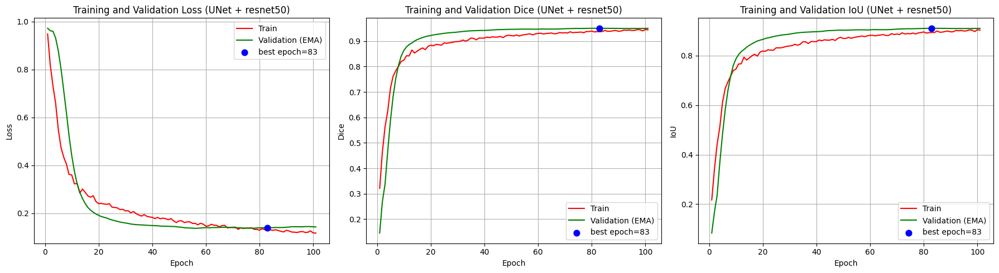

RINGKASAN EPOCH
Epoch Dijalankan     : 101 / 130
Best Epoch           : 83
Val Dice @ Best Epoch: 0.9507
Val Loss @ Best Epoch: 0.1400
Val IoU  @ Best Epoch: 0.9108
Training history plot saved to: /kaggle/working/training_history.png


In [31]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 31
# Training History Visualization
# =============================================================================
# REVISI (Version 8): setiap subplot sekarang menandai Best Epoch dengan
# titik biru + label "best epoch=N" pada legend (gaya sama seperti kurva
# Training/Validation Accuracy pada laporan Anda), dan dicetak ringkasan
# jumlah epoch yang benar-benar berjalan vs. total epoch yang dikonfigurasi.
# =============================================================================

epochs_run = len(history["train_loss"])
epochs_range = range(1, epochs_run + 1)

# Index 0-based ke dalam list history untuk epoch terbaik
_best_epoch_idx = best_epoch - 1

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --------------------------------------------------------------------------
# LOSS
# --------------------------------------------------------------------------
axes[0].plot(epochs_range, history["train_loss"], label="Train", color="red")
axes[0].plot(epochs_range, history["val_loss"], label="Validation (EMA)", color="green")
axes[0].scatter(
    [best_epoch], [history["val_loss"][_best_epoch_idx]],
    color="blue", s=60, zorder=5, label=f"best epoch={best_epoch}"
)
axes[0].set_title(f"Training and Validation Loss ({MODEL_NAME} + {ENCODER_NAME})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# --------------------------------------------------------------------------
# DICE SCORE
# --------------------------------------------------------------------------
axes[1].plot(epochs_range, history["train_dice"], label="Train", color="red")
axes[1].plot(epochs_range, history["val_dice"], label="Validation (EMA)", color="green")
axes[1].scatter(
    [best_epoch], [history["val_dice"][_best_epoch_idx]],
    color="blue", s=60, zorder=5, label=f"best epoch={best_epoch}"
)
axes[1].set_title(f"Training and Validation Dice ({MODEL_NAME} + {ENCODER_NAME})")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice")
axes[1].legend()
axes[1].grid(True)

# --------------------------------------------------------------------------
# IOU SCORE
# --------------------------------------------------------------------------
axes[2].plot(epochs_range, history["train_iou"], label="Train", color="red")
axes[2].plot(epochs_range, history["val_iou"], label="Validation (EMA)", color="green")
axes[2].scatter(
    [best_epoch], [history["val_iou"][_best_epoch_idx]],
    color="blue", s=60, zorder=5, label=f"best epoch={best_epoch}"
)
axes[2].set_title(f"Training and Validation IoU ({MODEL_NAME} + {ENCODER_NAME})")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("IoU")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()

history_plot_path = OUTPUT_DIR / "training_history.png"
plt.savefig(history_plot_path, dpi=150, bbox_inches="tight")

plt.show()

print("=" * 70)
print("RINGKASAN EPOCH")
print("=" * 70)
print(f"Epoch Dijalankan     : {epochs_run} / {NUM_EPOCHS}")
print(f"Best Epoch           : {best_epoch}")
print(f"Val Dice @ Best Epoch: {history['val_dice'][_best_epoch_idx]:.4f}")
print(f"Val Loss @ Best Epoch: {history['val_loss'][_best_epoch_idx]:.4f}")
print(f"Val IoU  @ Best Epoch: {history['val_iou'][_best_epoch_idx]:.4f}")
print("=" * 70)

print(f"Training history plot saved to: {history_plot_path}")


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 32
# Final Test Evaluation (TTA + Post-Processing)
# =============================================================================

In [32]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 32
# Final Test Evaluation (TTA + Post-Processing)
# =============================================================================
# Final Test Evaluation (TTA + Post-Processing)
# REVISI (Version 17): akumulasi confusion matrix piksel ditambahkan --
# lihat cell "Confusion Matrix" setelah ini untuk visualisasinya.
# =============================================================================
# HD95 fix: cases where the model misses a polyp entirely (empty prediction,
# non-empty ground truth) or hallucinates one (non-empty prediction, empty
# ground truth) are now penalized with the image diagonal distance instead of
# being silently skipped from the average.
# =============================================================================

print("=" * 70)
print("FINAL TEST EVALUATION")
print("=" * 70)

model.eval()

accuracy_metric.reset()
precision_metric.reset()
recall_metric.reset()

test_dice_scores = []
test_iou_scores = []
test_hd95_scores = []

hd95_penalized_count = 0
postprocess_zeroed_count = 0

# REVISI (Version 17): akumulasi confusion matrix piksel (TP/FP/FN/TN)
# di loop yang sama -- tidak perlu forward pass TTA tambahan.
cm_tp = cm_fp = cm_fn = cm_tn = 0

image_diagonal = float(np.sqrt(IMG_SIZE ** 2 + IMG_SIZE ** 2))

with torch.no_grad():

    for images, masks in tqdm(test_loader):

        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        probs = predict_with_tta(model, images, use_tta=USE_TTA)

        # ==================================================================
        # DICE & IOU (pre-post-processing, on TTA probabilities)
        # ==================================================================
        dice = dice_score(probs, masks, threshold=best_threshold, from_logits=False)
        iou = iou_score(probs, masks, threshold=best_threshold, from_logits=False)

        test_dice_scores.append(dice.item())
        test_iou_scores.append(iou.item())

        # ==================================================================
        # BINARY PREDICTION + POST-PROCESSING
        # ==================================================================
        raw_preds_np = (probs > best_threshold).float().cpu().numpy()
        preds_np = postprocess_batch(raw_preds_np)

        # Diagnostic: did post-processing ever erase a prediction entirely
        # (nonzero before, zero after)? This flags whether
        # POST_PROCESS_MIN_AREA is too aggressive for genuinely small polyps.
        for raw_i, clean_i in zip(raw_preds_np, preds_np):
            if raw_i.sum() > 0 and clean_i.sum() == 0:
                postprocess_zeroed_count += 1

        preds = torch.from_numpy(preds_np).to(DEVICE)

        # ==================================================================
        # CONFUSION MATRIX (pixel-level, akumulasi seluruh test set)
        # ==================================================================
        _cm_preds_flat = preds_np.astype(np.uint8).reshape(-1)
        _cm_masks_flat = masks.cpu().numpy().astype(np.uint8).reshape(-1)

        cm_tp += int(((_cm_preds_flat == 1) & (_cm_masks_flat == 1)).sum())
        cm_fp += int(((_cm_preds_flat == 1) & (_cm_masks_flat == 0)).sum())
        cm_fn += int(((_cm_preds_flat == 0) & (_cm_masks_flat == 1)).sum())
        cm_tn += int(((_cm_preds_flat == 0) & (_cm_masks_flat == 0)).sum())

        # ==================================================================
        # TORCHMETRICS
        # ==================================================================
        accuracy_metric.update(preds, masks.int())
        precision_metric.update(preds, masks.int())
        recall_metric.update(preds, masks.int())

        # ==================================================================
        # HD95
        # ==================================================================
        masks_np = masks.cpu().numpy()

        for pred_mask, gt_mask in zip(preds_np, masks_np):

            pred_mask = pred_mask.squeeze().astype(np.uint8)
            gt_mask = gt_mask.squeeze().astype(np.uint8)

            if pred_mask.sum() == 0 and gt_mask.sum() == 0:
                test_hd95_scores.append(0.0)

            elif pred_mask.sum() == 0 or gt_mask.sum() == 0:
                # Penalize instead of silently discarding this sample.
                test_hd95_scores.append(image_diagonal)
                hd95_penalized_count += 1

            else:
                try:
                    hd = hd95(pred_mask, gt_mask)
                    test_hd95_scores.append(hd)
                except Exception:
                    test_hd95_scores.append(image_diagonal)
                    hd95_penalized_count += 1

# =============================================================================
# FINAL RESULT
# =============================================================================
test_accuracy = accuracy_metric.compute().item()
test_precision = precision_metric.compute().item()
test_recall = recall_metric.compute().item()

mean_test_dice = np.mean(test_dice_scores)
mean_test_iou = np.mean(test_iou_scores)

mean_hd95 = np.mean(test_hd95_scores) if len(test_hd95_scores) > 0 else np.nan

print("=" * 70)
print("TEST RESULT (TTA + Post-Processing)")
print("=" * 70)

print(f"Dice Score : {mean_test_dice:.4f}")
print(f"IoU Score  : {mean_test_iou:.4f}")
print(f"Accuracy   : {test_accuracy:.4f}")
print(f"Precision  : {test_precision:.4f}")
print(f"Recall     : {test_recall:.4f}")
print(f"HD95       : {mean_hd95:.4f}")
print(f"HD95 pairs penalized (missed / hallucinated polyp) : {hd95_penalized_count}")
print(f"Predictions erased entirely by post-processing      : {postprocess_zeroed_count}")
print("(if this number is large relative to test set size, consider lowering")
print(" POST_PROCESS_MIN_AREA -- it may be discarding genuinely small polyps)")

print("=" * 70)

FINAL TEST EVALUATION


  0%|          | 0/27 [00:00<?, ?it/s]

TEST RESULT (TTA + Post-Processing)
Dice Score : 0.9510
IoU Score  : 0.9136
Accuracy   : 0.9918
Precision  : 0.9568
Recall     : 0.9685
HD95       : 12.9049
HD95 pairs penalized (missed / hallucinated polyp) : 1
Predictions erased entirely by post-processing      : 0
(if this number is large relative to test set size, consider lowering
 POST_PROCESS_MIN_AREA -- it may be discarding genuinely small polyps)


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 33
# Confusion Matrix (Pixel-Level, Full Test Set)
# =============================================================================

CONFUSION MATRIX (PIXEL-LEVEL, FULL TEST SET)
Total Piksel        : 109,576,192
True Positive  (TP) : 11,539,237   (polip, diprediksi benar sebagai polip)
True Negative  (TN) : 97,140,700   (bukan polip, diprediksi benar sebagai bukan polip)
False Positive (FP) : 520,569   (bukan polip, TAPI diprediksi sebagai polip)
False Negative (FN) : 375,686   (polip, TAPI terlewat/tidak diprediksi)
----------------------------------------------------------------------
Accuracy    : 0.9918  (cross-check vs torchmetrics: 0.9918)
Precision   : 0.9568  (cross-check vs torchmetrics: 0.9568)
Recall/Sens.: 0.9685  (cross-check vs torchmetrics: 0.9685)
Specificity : 0.9947
F1-Score    : 0.9626


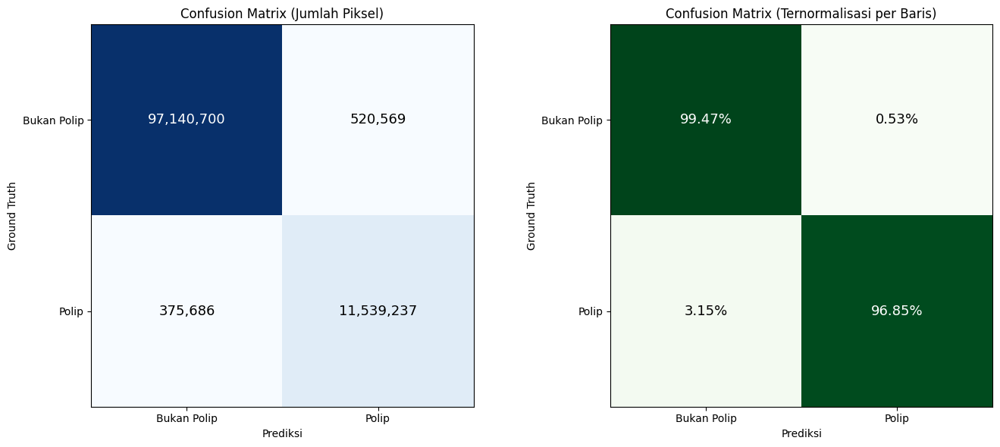

Confusion matrix disimpan ke: /kaggle/working/confusion_matrix.png


In [33]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 33
# Confusion Matrix (Pixel-Level, Full Test Set)
# =============================================================================

print("=" * 70)
print("CONFUSION MATRIX (PIXEL-LEVEL, FULL TEST SET)")
print("=" * 70)

confusion_counts = np.array([[cm_tn, cm_fp],
                              [cm_fn, cm_tp]])

total_pixels = cm_tn + cm_fp + cm_fn + cm_tp

# Metrik turunan dari confusion matrix (cross-check terhadap torchmetrics)
cm_accuracy = (cm_tp + cm_tn) / total_pixels
cm_precision = cm_tp / (cm_tp + cm_fp) if (cm_tp + cm_fp) > 0 else 0.0
cm_recall = cm_tp / (cm_tp + cm_fn) if (cm_tp + cm_fn) > 0 else 0.0
cm_specificity = cm_tn / (cm_tn + cm_fp) if (cm_tn + cm_fp) > 0 else 0.0
cm_f1 = (2 * cm_precision * cm_recall / (cm_precision + cm_recall)
         if (cm_precision + cm_recall) > 0 else 0.0)

print(f"Total Piksel        : {total_pixels:,}")
print(f"True Positive  (TP) : {cm_tp:,}   (polip, diprediksi benar sebagai polip)")
print(f"True Negative  (TN) : {cm_tn:,}   (bukan polip, diprediksi benar sebagai bukan polip)")
print(f"False Positive (FP) : {cm_fp:,}   (bukan polip, TAPI diprediksi sebagai polip)")
print(f"False Negative (FN) : {cm_fn:,}   (polip, TAPI terlewat/tidak diprediksi)")
print("-" * 70)
print(f"Accuracy    : {cm_accuracy:.4f}  (cross-check vs torchmetrics: {test_accuracy:.4f})")
print(f"Precision   : {cm_precision:.4f}  (cross-check vs torchmetrics: {test_precision:.4f})")
print(f"Recall/Sens.: {cm_recall:.4f}  (cross-check vs torchmetrics: {test_recall:.4f})")
print(f"Specificity : {cm_specificity:.4f}")
print(f"F1-Score    : {cm_f1:.4f}")
print("=" * 70)

# =============================================================================
# VISUALISASI: matriks hitung mentah + matriks ternormalisasi (persentase
# per baris ground truth), berdampingan.
# =============================================================================

class_labels = ["Bukan Polip", "Polip"]

row_sums = confusion_counts.sum(axis=1, keepdims=True)
confusion_normalized = confusion_counts / row_sums

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, matrix, title, fmt, cmap in [
    (axes[0], confusion_counts, "Confusion Matrix (Jumlah Piksel)", ",d", "Blues"),
    (axes[1], confusion_normalized, "Confusion Matrix (Ternormalisasi per Baris)", ".2%", "Greens"),
]:
    im = ax.imshow(matrix, cmap=cmap)

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(class_labels)
    ax.set_yticklabels(class_labels)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Ground Truth")
    ax.set_title(title)

    thresh = matrix.max() / 2.0
    for row in range(2):
        for col in range(2):
            value = matrix[row, col]
            text = f"{value:{fmt}}"
            color = "white" if value > thresh else "black"
            ax.text(col, row, text, ha="center", va="center", color=color, fontsize=13)

plt.tight_layout()

confusion_matrix_path = OUTPUT_DIR / "confusion_matrix.png"
plt.savefig(confusion_matrix_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Confusion matrix disimpan ke: {confusion_matrix_path}")
print("=" * 70)

# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 34
# Evaluation Transparency: Polyp-Only vs Full Test Set + Hallucination Rate
# =============================================================================

In [34]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 34
# Evaluation Transparency: Polyp-Only vs Full Test Set + Hallucination Rate
# =============================================================================

print("=" * 70)
print("EVALUATION TRANSPARENCY: POLYP-ONLY vs FULL TEST SET")
print("=" * 70)

model.eval()

full_dice_list, full_iou_list, full_hd95_list = [], [], []
polyp_only_dice_list, polyp_only_iou_list, polyp_only_hd95_list = [], [], []

positive_count = 0
negative_count = 0
hallucinated_test_count = 0

_eps = 1e-7

with torch.no_grad():

    for images, masks in tqdm(test_loader, desc="Recomputing per-image metrics"):

        images_gpu = images.to(DEVICE, non_blocking=True)

        probs = predict_with_tta(model, images_gpu, use_tta=USE_TTA)
        preds_np = (probs > best_threshold).float().cpu().numpy()
        preds_np = postprocess_batch(preds_np)

        masks_np = masks.numpy()

        for i in range(images.size(0)):

            pred_i = preds_np[i, 0].astype(np.uint8)
            gt_i = masks_np[i, 0].astype(np.uint8)

            intersection = float((pred_i * gt_i).sum())
            union_dice = float(pred_i.sum() + gt_i.sum())
            sample_dice = (2.0 * intersection + _eps) / (union_dice + _eps)

            union_iou = float(pred_i.sum() + gt_i.sum() - intersection)
            sample_iou = (intersection + _eps) / (union_iou + _eps)

            if pred_i.sum() == 0 and gt_i.sum() == 0:
                sample_hd95 = 0.0
            elif pred_i.sum() == 0 or gt_i.sum() == 0:
                sample_hd95 = image_diagonal
            else:
                try:
                    sample_hd95 = hd95(pred_i, gt_i)
                except Exception:
                    sample_hd95 = image_diagonal

            full_dice_list.append(sample_dice)
            full_iou_list.append(sample_iou)
            full_hd95_list.append(sample_hd95)

            if gt_i.sum() > 0:
                positive_count += 1
                polyp_only_dice_list.append(sample_dice)
                polyp_only_iou_list.append(sample_iou)
                polyp_only_hd95_list.append(sample_hd95)
            else:
                negative_count += 1
                # Image-level hallucination check: does the model still
                # report "Polyp Detected" on a genuinely normal image?
                polyp_area_percent = (pred_i.sum() / pred_i.size) * 100.0
                if polyp_area_percent >= MIN_POLYP_AREA_PERCENT:
                    hallucinated_test_count += 1

print(f"Total citra test        : {len(full_dice_list)}")
print(f"  - Polip-positif       : {positive_count}")
print(f"  - Normal (tanpa polip): {negative_count}")
print("-" * 70)
print(f"{'Metrik':10s} | {'Full Test Set':>15s} | {'Polyp-Only':>15s} | Sebanding literatur?")
print("-" * 70)
print(f"{'Dice':10s} | {np.mean(full_dice_list):15.4f} | {np.mean(polyp_only_dice_list):15.4f} | Ya (kolom kanan)")
print(f"{'IoU':10s} | {np.mean(full_iou_list):15.4f} | {np.mean(polyp_only_iou_list):15.4f} | Ya (kolom kanan)")
print(f"{'HD95':10s} | {np.mean(full_hd95_list):15.4f} | {np.mean(polyp_only_hd95_list):15.4f} | Ya (kolom kanan)")
print("-" * 70)
print("'Full Test Set' = representasi realistis performa di web Anda (termasuk")
print("kemampuan model mengenali citra normal dengan benar).")
print("'Polyp-Only' = angka yang SEBANDING dengan Tabel 2.1-2.7 di Bab 2.23")
print("proposal (DoubleU-Net, DCATNet, HSSAM-Net, dst -- semua dievaluasi")
print("murni pada citra polip-positif).")
print("")

hallucination_rate_test = (
    (hallucinated_test_count / negative_count * 100.0) if negative_count > 0 else 0.0
)
print("-" * 70)
print("HALLUCINATION RATE (citra normal yang salah dipicu jadi 'Polyp Detected')")
print(f"  {hallucinated_test_count} / {negative_count} citra normal ({hallucination_rate_test:.2f}%)")
if hallucination_rate_test == 0.0:
    print("  >>> Model TIDAK berhalusinasi sama sekali pada test set ini.")
elif hallucination_rate_test < 2.0:
    print("  >>> Halusinasi sangat rendah, dalam batas wajar untuk deployment.")
else:
    print("  >>> Halusinasi cukup terasa -- pertimbangkan threshold lebih tinggi")
    print("      (lihat tabel di Cell Threshold Search untuk trade-off-nya).")
print("-" * 70)

print("Rekomendasi: laporkan KEDUANYA (Polyp-Only & Full Test Set) plus angka")
print("Hallucination Rate di Bab 4 skripsi untuk transparansi penuh.")
print("=" * 70)

polyp_only_results = {
    "Polyp-Only Dice": round(float(np.mean(polyp_only_dice_list)), 4),
    "Polyp-Only IoU": round(float(np.mean(polyp_only_iou_list)), 4),
    "Polyp-Only HD95": round(float(np.mean(polyp_only_hd95_list)), 4),
    "Full Test Set Dice": round(float(np.mean(full_dice_list)), 4),
    "Full Test Set IoU": round(float(np.mean(full_iou_list)), 4),
    "Full Test Set HD95": round(float(np.mean(full_hd95_list)), 4),
    "Positive Samples": positive_count,
    "Negative Samples": negative_count,
    "Hallucinated Count": hallucinated_test_count,
    "Hallucination Rate (%)": round(hallucination_rate_test, 2),
}

polyp_only_df = pd.DataFrame([polyp_only_results])
polyp_only_path = OUTPUT_DIR / "polyp_only_vs_full_evaluation.csv"
polyp_only_df.to_csv(polyp_only_path, index=False)
print(f"\nDisimpan ke: {polyp_only_path}")


EVALUATION TRANSPARENCY: POLYP-ONLY vs FULL TEST SET


Recomputing per-image metrics:   0%|          | 0/27 [00:00<?, ?it/s]

Total citra test        : 418
  - Polip-positif       : 418
  - Normal (tanpa polip): 0
----------------------------------------------------------------------
Metrik     |   Full Test Set |      Polyp-Only | Sebanding literatur?
----------------------------------------------------------------------
Dice       |          0.9503 |          0.9503 | Ya (kolom kanan)
IoU        |          0.9126 |          0.9126 | Ya (kolom kanan)
HD95       |         12.9049 |         12.9049 | Ya (kolom kanan)
----------------------------------------------------------------------
'Full Test Set' = representasi realistis performa di web Anda (termasuk
kemampuan model mengenali citra normal dengan benar).
'Polyp-Only' = angka yang SEBANDING dengan Tabel 2.1-2.7 di Bab 2.23
proposal (DoubleU-Net, DCATNet, HSSAM-Net, dst -- semua dievaluasi
murni pada citra polip-positif).

----------------------------------------------------------------------
HALLUCINATION RATE (citra normal yang salah dipicu jadi 'Polyp D

# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 35
# Worst-Case Qualitative Analysis
# =============================================================================

WORST-CASE QUALITATIVE ANALYSIS


Scanning for worst cases:   0%|          | 0/27 [00:00<?, ?it/s]

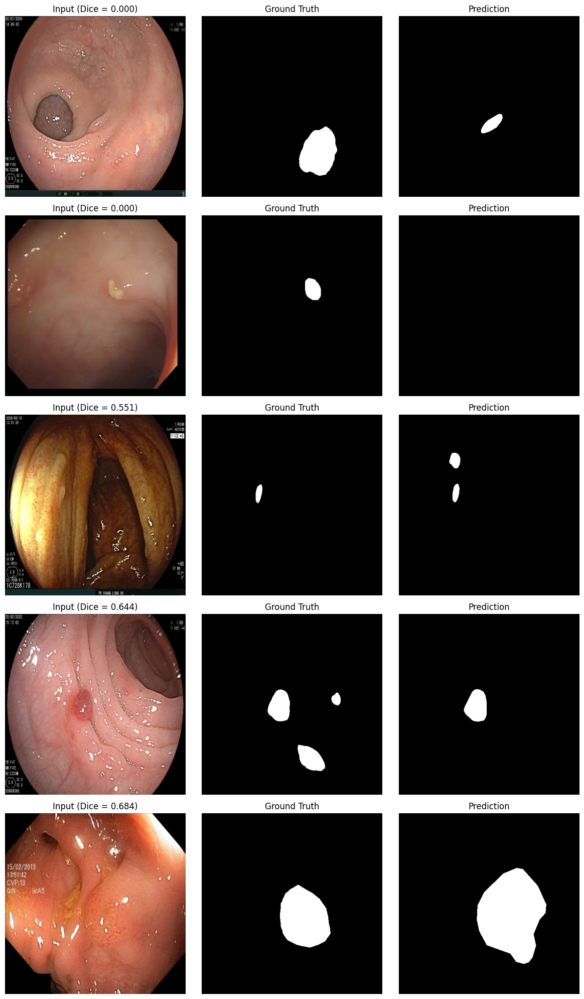

Worst-case figure saved to : /kaggle/working/worst_case_analysis.png
Dice scores (lowest 5) : [0.0, 0.0, 0.5508, 0.6438, 0.6836]


In [35]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 35
# Worst-Case Qualitative Analysis
# =============================================================================
# Surfaces the N lowest-Dice test samples for qualitative discussion in
# Bab 4 (e.g. checking whether failures cluster around flat/low-contrast
# polyps as described in Bab 2.2.1 of the proposal).
# =============================================================================

print("=" * 70)
print("WORST-CASE QUALITATIVE ANALYSIS")
print("=" * 70)

model.eval()

NUM_WORST_CASES = 5
worst_case_eps = 1e-7

worst_cases = []

with torch.no_grad():

    for images, masks in tqdm(test_loader, desc="Scanning for worst cases"):

        images_gpu = images.to(DEVICE, non_blocking=True)

        probs = predict_with_tta(model, images_gpu, use_tta=USE_TTA)

        preds_np = (probs > best_threshold).float().cpu().numpy()
        preds_np = postprocess_batch(preds_np)

        for i in range(images.size(0)):

            pred_i = preds_np[i, 0]
            gt_i = masks[i, 0].numpy()

            intersection = float((pred_i * gt_i).sum())
            union = float(pred_i.sum() + gt_i.sum())
            sample_dice = (2.0 * intersection + worst_case_eps) / (union + worst_case_eps)

            worst_cases.append((
                sample_dice,
                images[i].clone(),
                masks[i, 0].clone(),
                pred_i.copy()
            ))

worst_cases.sort(key=lambda item: item[0])
worst_cases = worst_cases[:NUM_WORST_CASES]

fig, axes = plt.subplots(len(worst_cases), 3, figsize=(12, 4 * len(worst_cases)))

if len(worst_cases) == 1:
    axes = np.expand_dims(axes, axis=0)

for row, (sample_dice, image_t, gt_t, pred_np_i) in enumerate(worst_cases):

    image = denormalize(image_t)
    gt = gt_t.numpy()

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Input (Dice = {sample_dice:.3f})")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(gt, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Ground Truth")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(pred_np_i, cmap="gray", vmin=0, vmax=1)
    axes[row, 2].set_title("Prediction")
    axes[row, 2].axis("off")

plt.tight_layout()

worst_case_path = OUTPUT_DIR / "worst_case_analysis.png"
plt.savefig(worst_case_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Worst-case figure saved to : {worst_case_path}")
print(f"Dice scores (lowest {NUM_WORST_CASES}) : "
      f"{[round(d, 4) for d, _, _, _ in worst_cases]}")

print("=" * 70)

# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 36
# Prediction Visualization (10 Sampel, Visualisasi Lengkap)
# =============================================================================

PREDICTION VISUALIZATION (10 SAMPLES, FULL DETAIL)


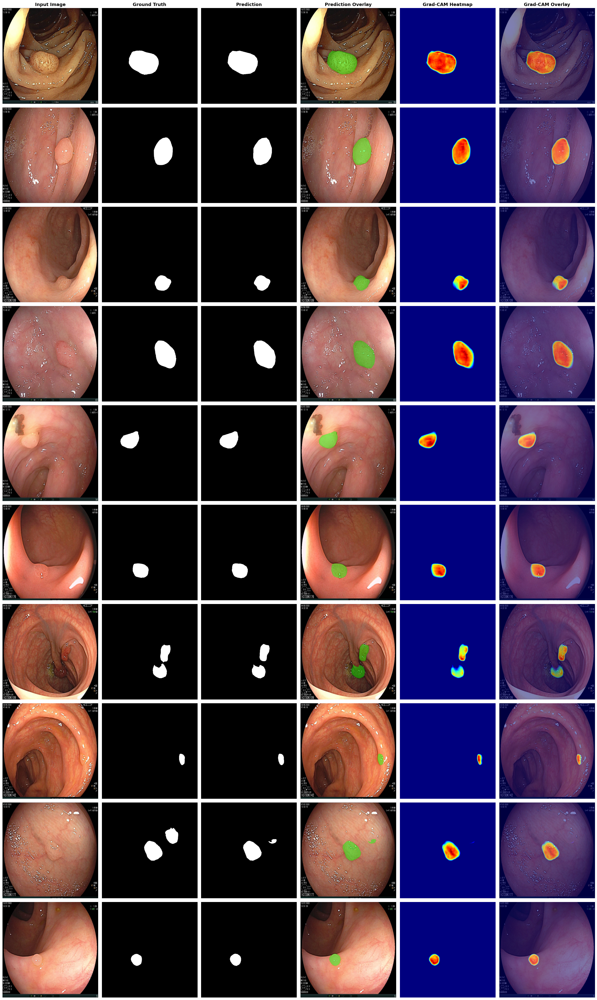

Visualisasi 10 sampel disimpan ke: /kaggle/working/prediction_visualization_10samples.png
VISUALIZATION COMPLETED


In [36]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 36
# Prediction Visualization (10 Sampel, Visualisasi Lengkap)
# =============================================================================
# REVISI (Version 8): 5 -> 10 sampel test, dan setiap sampel sekarang
# menampilkan SELURUH representasi visual yang tersedia -- Input, Ground
# Truth, Prediction, Prediction Overlay (mask hijau di atas citra asli),
# Grad-CAM Heatmap, dan Grad-CAM Overlay -- untuk analisis kualitatif yang
# lebih menyeluruh di Bab 4 skripsi.
# =============================================================================

from pytorch_grad_cam import GradCAM as _GradCAM_viz
from pytorch_grad_cam.utils.model_targets import SemanticSegmentationTarget as _SST_viz
from pytorch_grad_cam.utils.image import show_cam_on_image as _show_cam_viz

print("=" * 70)
print("PREDICTION VISUALIZATION (10 SAMPLES, FULL DETAIL)")
print("=" * 70)

model.eval()

NUM_VIS_SAMPLES = 10

_viz_target_layers = [model.decoder.blocks[-1]]
_viz_cam = _GradCAM_viz(model=model, target_layers=_viz_target_layers)


def _mask_overlay(rgb_image, binary_mask, color=(0.0, 1.0, 0.0), alpha=0.45):
    """Blend a binary mask onto an RGB image using a translucent color."""
    overlay = rgb_image.copy()
    color_arr = np.array(color)
    mask_bool = binary_mask.astype(bool)
    overlay[mask_bool] = (1 - alpha) * overlay[mask_bool] + alpha * color_arr
    return np.clip(overlay, 0.0, 1.0)


vis_images, vis_gts, vis_preds, vis_heatmaps, vis_overlays = [], [], [], [], []

collected = 0

for images, masks in test_loader:

    if collected >= NUM_VIS_SAMPLES:
        break

    images_gpu = images.to(DEVICE, non_blocking=True)

    probs = predict_with_tta(model, images_gpu, use_tta=USE_TTA)
    preds_np = (probs > best_threshold).float().cpu().numpy()
    preds_np = postprocess_batch(preds_np)

    for i in range(images.size(0)):

        if collected >= NUM_VIS_SAMPLES:
            break

        rgb_image = denormalize(images[i])
        gt = masks[i, 0].numpy()
        pred = preds_np[i, 0]

        single_tensor = images_gpu[i:i + 1]

        with torch.no_grad():
            single_output = model(single_tensor)
        single_pred_mask = (torch.sigmoid(single_output) > best_threshold).float()[0, 0].cpu().numpy()

        gradcam_target = [_SST_viz(0, single_pred_mask)]
        grayscale_cam = _viz_cam(input_tensor=single_tensor, targets=gradcam_target)[0]

        gradcam_overlay = _show_cam_viz(rgb_image.astype(np.float32), grayscale_cam, use_rgb=True)

        vis_images.append(rgb_image)
        vis_gts.append(gt)
        vis_preds.append(pred)
        vis_heatmaps.append(grayscale_cam)
        vis_overlays.append(gradcam_overlay)

        collected += 1

col_titles = [
    "Input Image", "Ground Truth", "Prediction",
    "Prediction Overlay", "Grad-CAM Heatmap", "Grad-CAM Overlay"
]

fig, axes = plt.subplots(NUM_VIS_SAMPLES, 6, figsize=(24, 4 * NUM_VIS_SAMPLES))

for row in range(NUM_VIS_SAMPLES):

    axes[row, 0].imshow(vis_images[row])
    axes[row, 1].imshow(vis_gts[row], cmap="gray", vmin=0, vmax=1)
    axes[row, 2].imshow(vis_preds[row], cmap="gray", vmin=0, vmax=1)
    axes[row, 3].imshow(_mask_overlay(vis_images[row], vis_preds[row]))
    axes[row, 4].imshow(vis_heatmaps[row], cmap="jet")
    axes[row, 5].imshow(vis_overlays[row])

    for col in range(6):
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(col_titles[col], fontsize=13, fontweight="bold")

plt.tight_layout()

full_vis_path = OUTPUT_DIR / "prediction_visualization_10samples.png"
plt.savefig(full_vis_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Visualisasi {NUM_VIS_SAMPLES} sampel disimpan ke: {full_vis_path}")
print("=" * 70)
print("VISUALIZATION COMPLETED")
print("=" * 70)

# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 37
# Grad-CAM Visualization
# =============================================================================

GRAD-CAM VISUALIZATION


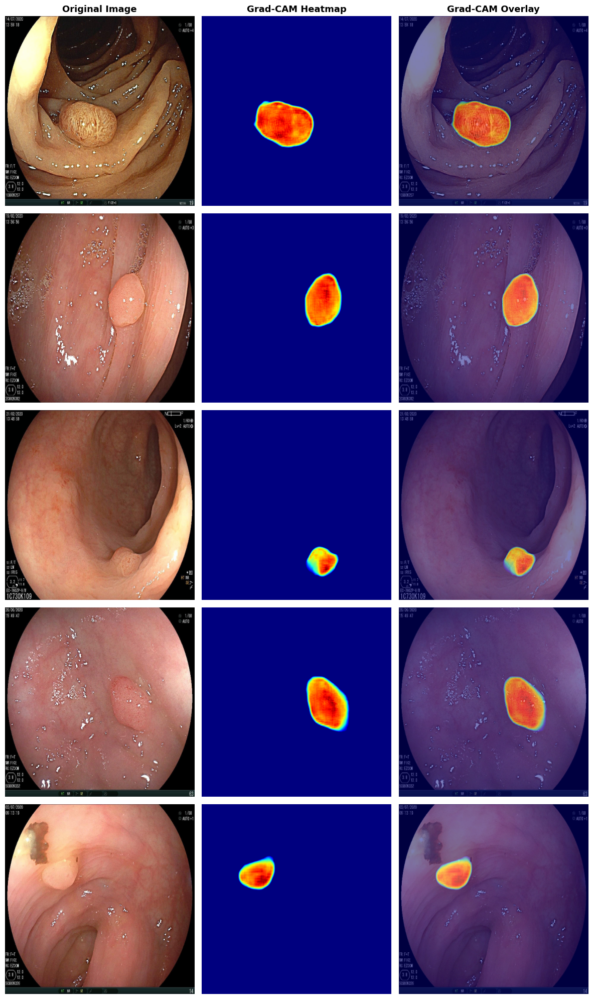

Grad-CAM grid disimpan ke: /kaggle/working/gradcam_visualization.png
GRAD-CAM COMPLETED


In [37]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 37
# Grad-CAM Visualization
# =============================================================================
# FIXED (Version 4): pytorch-grad-cam assumes a scalar classification output
# by default. A segmentation model outputs a full spatial map (1, H, W), so
# `loss.backward()` previously failed with "grad can be implicitly created
# only for scalar outputs". Fixed using SemanticSegmentationTarget, which
# reduces the spatial output to a scalar by summing over the predicted
# foreground region -- the standard pytorch-grad-cam approach for
# segmentation models.
#
# Target layer changed from `model.encoder.layer4[-1]` to
# `model.decoder.blocks[-1]`, matching the methodology stated in proposal
# Bab 2.12.1: "perhitungan Grad-CAM ini secara spesifik diterapkan pada
# lapisan decoder terakhir dari jaringan".
#
# REVISI (Version 8): skema warna kustom (merah/biru berbasis threshold)
# dihapus. Kembali memakai visualisasi BAWAAN dari pytorch-grad-cam
# (`show_cam_on_image`, colormap jet standar), ditampilkan dalam format
# 3 kolom (Original Image / Grad-CAM Heatmap / Grad-CAM Overlay) x N sampel,
# konsisten dengan gaya figur pada literatur.
# =============================================================================

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import SemanticSegmentationTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

print("=" * 70)
print("GRAD-CAM VISUALIZATION")
print("=" * 70)

target_layers = [model.decoder.blocks[-1]]

cam = GradCAM(model=model, target_layers=target_layers)

model.eval()

NUM_GRADCAM_SAMPLES = 5

images, masks = next(iter(test_loader))

fig, axes = plt.subplots(NUM_GRADCAM_SAMPLES, 3, figsize=(12, 4 * NUM_GRADCAM_SAMPLES))

for row in range(NUM_GRADCAM_SAMPLES):

    image_tensor = images[row:row + 1].to(DEVICE)

    with torch.no_grad():
        output = model(image_tensor)

    # Category 0: single output channel (binary segmentation). The mask
    # focuses Grad-CAM's attribution on the region the model predicted as
    # polyp.
    prediction_mask_np = (torch.sigmoid(output) > best_threshold).float()[0, 0].cpu().numpy()
    targets = [SemanticSegmentationTarget(0, prediction_mask_np)]

    grayscale_cam = cam(input_tensor=image_tensor, targets=targets)[0]

    rgb_image = denormalize(image_tensor[0].cpu())
    gradcam_overlay = show_cam_on_image(rgb_image.astype(np.float32), grayscale_cam, use_rgb=True)

    axes[row, 0].imshow(rgb_image)
    axes[row, 1].imshow(grayscale_cam, cmap="jet")
    axes[row, 2].imshow(gradcam_overlay)

    for col in range(3):
        axes[row, col].axis("off")

    if row == 0:
        axes[row, 0].set_title("Original Image", fontsize=13, fontweight="bold")
        axes[row, 1].set_title("Grad-CAM Heatmap", fontsize=13, fontweight="bold")
        axes[row, 2].set_title("Grad-CAM Overlay", fontsize=13, fontweight="bold")

plt.tight_layout()

gradcam_grid_path = OUTPUT_DIR / "gradcam_visualization.png"
plt.savefig(gradcam_grid_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Grad-CAM grid disimpan ke: {gradcam_grid_path}")
print("=" * 70)
print("GRAD-CAM COMPLETED")
print("=" * 70)

# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 38
# Single Image Inference
# =============================================================================

SINGLE IMAGE INFERENCE


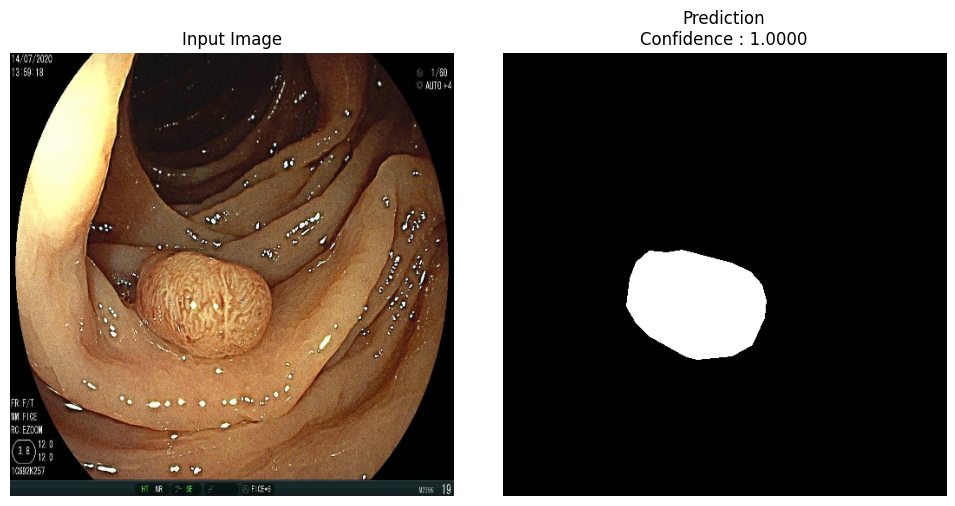

INFERENCE RESULT
Confidence Score : 1.0000
Polyp Area       : 6.02%
Prediction       : Polyp Detected


In [38]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 38
# Single Image Inference
# =============================================================================
# Decision rule now requires a minimum predicted area (not just >0 pixels)
# to reduce sensitivity to single-pixel false positives, and uses the same
# TTA + post-processing pipeline as the final evaluation for consistency.
# =============================================================================

print("=" * 70)
print("SINGLE IMAGE INFERENCE")
print("=" * 70)

model.eval()

# MIN_POLYP_AREA_PERCENT is defined once in Global Config (Cell 3) and
# shared with the deployment-ready inference function (Cell 34).

images, masks = next(iter(test_loader))
sample_image = images[0:1].to(DEVICE)

with torch.no_grad():
    probs = predict_with_tta(model, sample_image, use_tta=USE_TTA)

confidence = probs.max().item()

pred_np = (probs > best_threshold).float().cpu().numpy()
pred_np = postprocess_mask(pred_np[0, 0])

image = denormalize(sample_image[0].cpu())

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(image)
axes[0].set_title("Input Image")
axes[0].axis("off")

axes[1].imshow(pred_np, cmap="gray")
axes[1].set_title(f"Prediction\nConfidence : {confidence:.4f}")
axes[1].axis("off")

plt.tight_layout()
plt.show()

polyp_pixels = np.sum(pred_np)
total_pixels = pred_np.size
polyp_percentage = (polyp_pixels / total_pixels) * 100

print("=" * 70)
print("INFERENCE RESULT")
print("=" * 70)

print(f"Confidence Score : {confidence:.4f}")
print(f"Polyp Area       : {polyp_percentage:.2f}%")

if polyp_percentage >= MIN_POLYP_AREA_PERCENT:
    print("Prediction       : Polyp Detected")
else:
    print("Prediction       : Normal")

print("=" * 70)

# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 39
# Deployment-Ready Inference Function (for Flask Web App)
# =============================================================================

DEPLOYMENT FUNCTION -- QUICK TEST
Image              : bkai_000002.jpeg
Polyp Detected     : True
Polyp Area %       : 6.02
Confidence         : 1.0
Mask shape         : (512, 512)
Mask (orig size)   : (995, 1280)
Grad-CAM overlay   : (512, 512, 3)


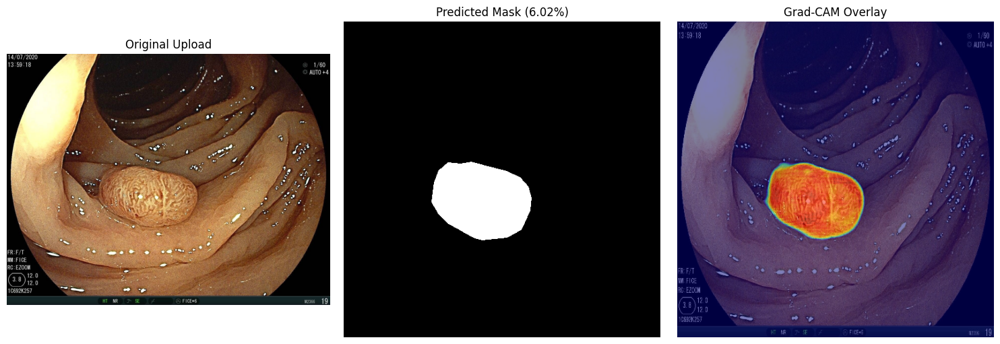

run_inference() siap disalin ke Flask app.py Anda.


In [39]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 39
# Deployment-Ready Inference Function (for Flask Web App)
# =============================================================================

def run_inference(image_input,
                   model=model,
                   threshold=best_threshold,
                   use_tta=USE_TTA,
                   use_multiscale=USE_MULTISCALE_TTA,
                   generate_gradcam=True,
                   fast_mode=False):
    """
    Fungsi inferensi end-to-end siap pakai untuk deployment (Flask, dsb).

    Parameters
    ----------
    image_input : str | Path | np.ndarray
        Path ke file gambar, ATAU array numpy yang sudah dibaca sebelumnya
        (mis. dari file upload Flask). Menerima RGB, grayscale (2D), maupun
        RGBA (4 channel) -- otomatis dikonversi ke RGB.
    fast_mode : bool
        True  -> matikan TTA & multi-scale, 1x forward pass saja (lebih
                 cepat, akurasi sedikit lebih rendah). Cocok untuk respons
                 real-time di web.
        False -> gunakan TTA + multi-scale penuh (default, akurasi terbaik,
                 lebih lambat -- lihat Cell Benchmark untuk perkiraan waktu).

    Returns
    -------
    dict. Jika berhasil, key "error" bernilai None dan berisi:
        mask, mask_original_size, polyp_detected, polyp_area_percent,
        confidence, dan gradcam_overlay (jika generate_gradcam=True).
    Jika gagal, key "error" berisi pesan error (string) dan key lain None --
    cek `result["error"]` di sisi Flask sebelum memakai key lainnya.
    """

    result = {
        "error": None, "mask": None, "mask_original_size": None,
        "polyp_detected": None, "polyp_area_percent": None,
        "confidence": None, "gradcam_overlay": None
    }

    try:
        model.eval()

        if isinstance(image_input, (str, Path)):
            raw_bgr = cv2.imread(str(image_input))
            if raw_bgr is None:
                result["error"] = f"Cannot read image: {image_input}"
                return result
            raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
        else:
            raw_rgb = np.asarray(image_input)

            # Robustly normalize whatever channel format arrives from a web
            # upload (grayscale scans, RGBA screenshots, etc.) to clean RGB.
            if raw_rgb.ndim == 2:
                raw_rgb = cv2.cvtColor(raw_rgb, cv2.COLOR_GRAY2RGB)
            elif raw_rgb.ndim == 3 and raw_rgb.shape[2] == 4:
                raw_rgb = cv2.cvtColor(raw_rgb, cv2.COLOR_RGBA2RGB)
            elif raw_rgb.ndim == 3 and raw_rgb.shape[2] == 1:
                raw_rgb = cv2.cvtColor(raw_rgb[:, :, 0], cv2.COLOR_GRAY2RGB)
            elif not (raw_rgb.ndim == 3 and raw_rgb.shape[2] == 3):
                result["error"] = f"Unsupported image shape: {raw_rgb.shape}"
                return result

        if raw_rgb.size == 0:
            result["error"] = "Empty image."
            return result

        original_h, original_w = raw_rgb.shape[:2]

        transformed = valid_transform(image=raw_rgb)
        image_tensor = transformed["image"].unsqueeze(0).to(DEVICE)

        effective_tta = False if fast_mode else use_tta
        effective_multiscale = False if fast_mode else use_multiscale

        with torch.no_grad():
            probs = predict_with_tta(
                model, image_tensor,
                use_tta=effective_tta, use_multiscale=effective_multiscale
            )

        confidence = float(probs.max().item())

        pred_np = (probs > threshold).float().cpu().numpy()[0, 0]
        pred_np = postprocess_mask(pred_np)

        polyp_pixels = int(pred_np.sum())
        total_pixels = pred_np.size
        polyp_area_percent = (polyp_pixels / total_pixels) * 100.0
        polyp_detected = polyp_area_percent >= MIN_POLYP_AREA_PERCENT

        mask_original_size = cv2.resize(
            pred_np.astype(np.uint8), (original_w, original_h),
            interpolation=cv2.INTER_NEAREST
        )

        result.update({
            "mask": pred_np.astype(np.uint8),
            "mask_original_size": mask_original_size,
            "polyp_detected": bool(polyp_detected),
            "polyp_area_percent": round(polyp_area_percent, 2),
            "confidence": round(confidence, 4),
        })

        if generate_gradcam:

            with torch.no_grad():
                output = model(image_tensor)

            prediction_mask_np = (torch.sigmoid(output) > threshold).float()[0, 0].cpu().numpy()
            gradcam_targets = [SemanticSegmentationTarget(0, prediction_mask_np)]

            grayscale_cam = cam(input_tensor=image_tensor, targets=gradcam_targets)[0]

            rgb_resized = cv2.resize(raw_rgb, (IMG_SIZE, IMG_SIZE)).astype(np.float32) / 255.0
            overlay = show_cam_on_image(rgb_resized, grayscale_cam, use_rgb=True)

            result["gradcam_overlay"] = overlay

        return result

    except Exception as e:
        result["error"] = f"{type(e).__name__}: {e}"
        return result


# =============================================================================
# QUICK TEST: run the function on one real test image end-to-end
# =============================================================================
print("=" * 70)
print("DEPLOYMENT FUNCTION -- QUICK TEST")
print("=" * 70)

_test_image_path = test_dataset.image_files[0]
_result = run_inference(_test_image_path)

if _result["error"] is not None:
    print(f"ERROR: {_result['error']}")
else:
    print(f"Image              : {_test_image_path.name}")
    print(f"Polyp Detected     : {_result['polyp_detected']}")
    print(f"Polyp Area %       : {_result['polyp_area_percent']}")
    print(f"Confidence         : {_result['confidence']}")
    print(f"Mask shape         : {_result['mask'].shape}")
    print(f"Mask (orig size)   : {_result['mask_original_size'].shape}")
    print(f"Grad-CAM overlay   : {_result['gradcam_overlay'].shape}")

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(cv2.cvtColor(cv2.imread(str(_test_image_path)), cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original Upload")
    axes[0].axis("off")

    axes[1].imshow(_result["mask"], cmap="gray")
    axes[1].set_title(f"Predicted Mask ({_result['polyp_area_percent']}%)")
    axes[1].axis("off")

    axes[2].imshow(_result["gradcam_overlay"])
    axes[2].set_title("Grad-CAM Overlay")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

print("=" * 70)
print("run_inference() siap disalin ke Flask app.py Anda.")
print("=" * 70)

# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 40
# Inference Speed Benchmark (Fast Mode vs Full TTA Mode)
# =============================================================================

In [40]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 40
# Inference Speed Benchmark (Fast Mode vs Full TTA Mode)
# =============================================================================
# Mengukur latensi rata-rata per gambar untuk membantu Anda memilih trade-off
# kecepatan vs akurasi yang sesuai untuk web app (mis. real-time upload vs
# analisis batch offline).
# =============================================================================

import time

print("=" * 70)
print("INFERENCE SPEED BENCHMARK")
print("=" * 70)

BENCHMARK_NUM_IMAGES = min(20, len(test_dataset))
_benchmark_paths = test_dataset.image_files[:BENCHMARK_NUM_IMAGES]

def _benchmark_mode(fast_mode: bool, generate_gradcam: bool):

    # Warm-up (exclude first-call CUDA initialization overhead from timing)
    _ = run_inference(_benchmark_paths[0], fast_mode=fast_mode,
                       generate_gradcam=generate_gradcam)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    for path in _benchmark_paths:
        _ = run_inference(path, fast_mode=fast_mode, generate_gradcam=generate_gradcam)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start
    return elapsed / len(_benchmark_paths) * 1000.0  # ms/image


modes = [
    ("Fast mode (no TTA, no Grad-CAM)",        True,  False),
    ("Fast mode (no TTA, with Grad-CAM)",      True,  True),
    ("Full mode (TTA+multiscale, no Grad-CAM)", False, False),
    ("Full mode (TTA+multiscale, with Grad-CAM)", False, True),
]

print(f"Benchmarking on {BENCHMARK_NUM_IMAGES} test images, device = {DEVICE}")
print("-" * 70)

for label, fast, gradcam in modes:
    ms_per_image = _benchmark_mode(fast_mode=fast, generate_gradcam=gradcam)
    print(f"{label:45s} : {ms_per_image:7.1f} ms/image")

print("-" * 70)
print("Rekomendasi:")
print("- Web app dengan respons real-time (user menunggu)   -> fast_mode=True")
print("- Analisis batch / laporan medis offline              -> fast_mode=False")
print("- Grad-CAM hanya generate saat user memintanya (opsional per-request),")
print("  bukan default di setiap upload, untuk hemat waktu respons.")
print("=" * 70)

INFERENCE SPEED BENCHMARK
Benchmarking on 20 test images, device = cuda
----------------------------------------------------------------------
Fast mode (no TTA, no Grad-CAM)               :    78.9 ms/image
Fast mode (no TTA, with Grad-CAM)             :   268.8 ms/image
Full mode (TTA+multiscale, no Grad-CAM)       :  1532.7 ms/image
Full mode (TTA+multiscale, with Grad-CAM)     :  1226.5 ms/image
----------------------------------------------------------------------
Rekomendasi:
- Web app dengan respons real-time (user menunggu)   -> fast_mode=True
- Analisis batch / laporan medis offline              -> fast_mode=False
- Grad-CAM hanya generate saat user memintanya (opsional per-request),
  bukan default di setiap upload, untuk hemat waktu respons.


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 41
# Export Results
# =============================================================================

In [41]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 41
# Export Results
# =============================================================================

print("=" * 70)
print("EXPORT RESULTS")
print("=" * 70)

results = {
    "Best Epoch": best_epoch,
    "Best Dice Validation (EMA)": round(best_dice, 4),
    "Best Threshold": round(best_threshold, 2),
    "Test Dice (TTA+PostProc)": round(mean_test_dice, 4),
    "Test IoU (TTA+PostProc)": round(mean_test_iou, 4),
    "Accuracy": round(test_accuracy, 4),
    "Precision": round(test_precision, 4),
    "Recall": round(test_recall, 4),
    "HD95": round(mean_hd95, 4),
    "pos_weight (BCE)": round(pos_weight_value, 2),
    "Tversky alpha": TVERSKY_ALPHA,
    "Tversky beta": TVERSKY_BETA,
    "Focal Tversky gamma": FOCAL_TVERSKY_GAMMA,
    "EMA decay": EMA_DECAY if USE_EMA else None,
    "TTA": USE_TTA
}

results_df = pd.DataFrame([results])
results_path = OUTPUT_DIR / "evaluation_results.csv"
results_df.to_csv(results_path, index=False)

history_df = pd.DataFrame(history)
history_path = OUTPUT_DIR / "training_history.csv"
history_df.to_csv(history_path, index=False)

print("Evaluation Result Saved :")
print(results_path)
print()
print("Training History Saved :")
print(history_path)

print("=" * 70)

EXPORT RESULTS
Evaluation Result Saved :
/kaggle/working/evaluation_results.csv

Training History Saved :
/kaggle/working/training_history.csv


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 42
# Save Final Artifacts
# =============================================================================

In [42]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 42
# Save Final Artifacts
# =============================================================================

print("=" * 70)
print("SAVE FINAL ARTIFACTS")
print("=" * 70)

config = {
    "MODEL_NAME": MODEL_NAME,
    "ENCODER_NAME": ENCODER_NAME,
    "ENCODER_WEIGHTS": ENCODER_WEIGHTS,
    "DECODER_ATTENTION": DECODER_ATTENTION,
    "IMG_SIZE": IMG_SIZE,
    "BATCH_SIZE": BATCH_SIZE,
    "NUM_EPOCHS": NUM_EPOCHS,
    "LEARNING_RATE": LEARNING_RATE,
    "ENCODER_LR_MULTIPLIER": ENCODER_LR_MULTIPLIER,
    "WARMUP_EPOCHS": WARMUP_EPOCHS,
    "WEIGHT_DECAY": WEIGHT_DECAY,
    "FREEZE_ENCODER": FREEZE_ENCODER,
    "UNFREEZE_EPOCH": UNFREEZE_EPOCH,
    "USE_EMA": USE_EMA,
    "EMA_DECAY": EMA_DECAY,
    "USE_TTA": USE_TTA,
    "LOVASZ_WEIGHT": LOVASZ_WEIGHT,
    "TVERSKY_ALPHA": TVERSKY_ALPHA,
    "TVERSKY_BETA": TVERSKY_BETA,
    "FOCAL_TVERSKY_GAMMA": FOCAL_TVERSKY_GAMMA,
    "POS_WEIGHT": pos_weight_value,
    "POST_PROCESS_MIN_AREA": POST_PROCESS_MIN_AREA,
    "USE_CONTOUR_SMOOTHING": USE_CONTOUR_SMOOTHING,
    "CONTOUR_SMOOTHING_EPSILON_RATIO": CONTOUR_SMOOTHING_EPSILON_RATIO,
    "USE_BOUNDARY_LOSS": USE_BOUNDARY_LOSS,
    "BOUNDARY_LOSS_WEIGHT": BOUNDARY_LOSS_WEIGHT,
    "BEST_EPOCH": best_epoch,
    "BEST_DICE": float(best_dice),
    "USE_MULTISCALE_TTA": USE_MULTISCALE_TTA,
    "MULTISCALE_TTA_SCALES": MULTISCALE_TTA_SCALES,
    "BEST_THRESHOLD": float(best_threshold)
}

config_path = OUTPUT_DIR / "config.json"

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

print("Configuration Saved :")
print(config_path)
print()
print("Best Model :")
print(OUTPUT_DIR / MODEL_SAVE_NAME)

print("=" * 70)

SAVE FINAL ARTIFACTS
Configuration Saved :
/kaggle/working/config.json

Best Model :
/kaggle/working/best_model.pth


# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 43
# Experiment Summary FINAL
# =============================================================================

In [43]:
# =============================================================================
# PIXEL-T | Scenario 1 - Version 22 - Version 4 No Normal
# Cell 43
# Experiment Summary FINAL
# =============================================================================
# REVISI (Version 17): tambah info durasi training & total durasi
# notebook, plus ringkasan confusion matrix.
# =============================================================================

print("=" * 70)
print("PIXEL-T")
print("Scenario 1 (U-Net + ResNet50) - Version 7 (FINAL)")
print("EXPERIMENT SUMMARY")
print("=" * 70)

print(f"Model               : {MODEL_NAME}")
print(f"Encoder             : {ENCODER_NAME}")
print(f"Input Size          : {IMG_SIZE}")
print(f"Batch Size          : {BATCH_SIZE}")
print(f"Epochs Run          : {len(history['train_loss'])} / {NUM_EPOCHS}")

print("-" * 70)

print(f"Best Epoch          : {best_epoch}")
print(f"Validation Dice(EMA): {best_dice:.4f}")
print(f"Best Threshold      : {best_threshold:.2f}")
print(f"Training Duration   : {format_duration(training_duration_seconds)}")
print(f"Total Durasi Notebook: {format_duration(time.time() - NOTEBOOK_START_TIME)} (sejak Cell Import Libraries)")

print("-" * 70)

print("FULL TEST SET (representasi realistis deployment web)")
print(f"  Dice              : {mean_test_dice:.4f}")
print(f"  IoU               : {mean_test_iou:.4f}")
print(f"  Accuracy          : {test_accuracy:.4f}")
print(f"  Precision         : {test_precision:.4f}")
print(f"  Recall            : {test_recall:.4f}")
print(f"  HD95              : {mean_hd95:.4f}")
# REVISI (Version 14): tampilkan hd95_penalized_count langsung di sini --
# ini diagnostik kunci untuk membedakan "HD95 tinggi karena kasus gagal
# total (deteksi)" vs "HD95 tinggi karena batas kurang presisi (boundary)".
print(f"  HD95 gagal-total  : {hd95_penalized_count}/{len(test_hd95_scores)} citra "
      f"(mask kosong total di prediksi ATAU ground truth)")
print(f"  Hallucination Rate: {hallucination_rate_test:.2f}% "
      f"({hallucinated_test_count}/{negative_count} citra normal)")

print("-" * 70)

print("POLYP-ONLY (sebanding dengan literatur Bab 2.23)")
print(f"  Dice              : {np.mean(polyp_only_dice_list):.4f}")
print(f"  IoU               : {np.mean(polyp_only_iou_list):.4f}")
print(f"  HD95              : {np.mean(polyp_only_hd95_list):.4f}")

print("-" * 70)

print("Optimizations Applied")
print(f"* pos_weight (BCE)        : {pos_weight_value:.2f}")
print(f"* Focal Tversky (a/b/g)   : {TVERSKY_ALPHA}/{TVERSKY_BETA}/{FOCAL_TVERSKY_GAMMA}")
print(f"* Lovasz-Hinge Weight     : {LOVASZ_WEIGHT} (surrogate langsung IoU/Jaccard)")
print(f"* Differential LR         : encoder x{ENCODER_LR_MULTIPLIER}")
print(f"* Warmup + Cosine         : {WARMUP_EPOCHS} warmup epochs")
print(f"* EMA                     : {USE_EMA} (decay={EMA_DECAY})")
print(f"* TTA (5-way flip+rotate + multiscale): {USE_TTA} / {USE_MULTISCALE_TTA} {MULTISCALE_TTA_SCALES}")
print(f"* Post-processing         : min_area={POST_PROCESS_MIN_AREA}px, "
      f"contour_smoothing={USE_CONTOUR_SMOOTHING}")
print(f"* Boundary Loss           : {USE_BOUNDARY_LOSS}" + (f" (weight={BOUNDARY_LOSS_WEIGHT})" if USE_BOUNDARY_LOSS else " (opsional, tidak dipakai di run ini)"))

print("-" * 70)

print("CONFUSION MATRIX (PIXEL-LEVEL)")
print(f"  TP={cm_tp:,}  FP={cm_fp:,}  FN={cm_fn:,}  TN={cm_tn:,}")
print(f"  Precision={cm_precision:.4f}  Recall/Sens.={cm_recall:.4f}  Specificity={cm_specificity:.4f}  F1={cm_f1:.4f}")

print("-" * 70)

print("Generated Files")
print(f"* {MODEL_SAVE_NAME}")
print("* evaluation_results.csv")
print("* polyp_only_vs_full_evaluation.csv")
print("* training_history.csv")
print("* training_history.png")
print("* worst_case_analysis.png")
print("* config.json")
print("* confusion_matrix.png")

print("=" * 70)
print("STATUS: VERSI FINAL SKENARIO 1 (U-Net + ResNet50)")
print("Model ini siap dibandingkan dengan Skenario 2/3 (U-Net biasa / ResNet")
print("biasa) di Bab 4, dan siap di-deploy ke web via pixelt_inference.py +")
print("flask_app_example.py.")
print("=" * 70)
print("PIXEL-T Scenario 1 Version 7 (FINAL) Completed Successfully.")
print("=" * 70)


PIXEL-T
Scenario 1 (U-Net + ResNet50) - Version 7 (FINAL)
EXPERIMENT SUMMARY
Model               : UNet
Encoder             : resnet50
Input Size          : 512
Batch Size          : 16
Epochs Run          : 101 / 130
----------------------------------------------------------------------
Best Epoch          : 83
Validation Dice(EMA): 0.9507
Best Threshold      : 0.55
Training Duration   : 5 jam 58 menit 25 detik
Total Durasi Notebook: 6 jam 30 menit 13 detik (sejak Cell Import Libraries)
----------------------------------------------------------------------
FULL TEST SET (representasi realistis deployment web)
  Dice              : 0.9510
  IoU               : 0.9136
  Accuracy          : 0.9918
  Precision         : 0.9568
  Recall            : 0.9685
  HD95              : 12.9049
  HD95 gagal-total  : 1/418 citra (mask kosong total di prediksi ATAU ground truth)
  Hallucination Rate: 0.00% (0/0 citra normal)
----------------------------------------------------------------------
POLYP